<a href="https://colab.research.google.com/github/ParthShah7099/Crowd_Decoder_Unsupervised_Learning/blob/main/UL_PR1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛍️ CROWD DECODER — Mall Customer Segmentation
### Unsupervised Learning · PR 1 · Red & White Skill Education

**Prepared by:** Parth Shah<br>
**Algorithms:** K-Means · Agglomerative Hierarchical · DBSCAN<br>
**Dataset:** [Mall Customer Segmentation Data — Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) (200 customers, 5 columns, CC0: Public Domain)

> 200 shoppers. No labels, no names — just gender, age, income and a spending score.
> The job: let three different algorithms find the customer groups on their own, compare them honestly, and turn the best result into decisions a mall can actually use.

**Contents**
1. Task 1 — Data Loading & Exploratory Data Analysis (EDA)
2. Task 2 — Feature Scaling & Feature Selection
3. Task 3 — K-Means Clustering
4. Task 4 — Agglomerative Hierarchical Clustering
5. Task 5 — DBSCAN Clustering
6. Task 6 — Algorithm Comparison & Business Insights
7. Task 7 — Notebook Quality, Structure & Submission

## ⚙️ Setup — Libraries & Plot Style

Only the basic libraries are imported here. Every scikit-learn / SciPy tool is imported inside the task where it is first used, so it's clear which step needs what.

In [1]:
# ─── Basic libraries ───
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ─── Poore notebook ka ek hi consistent plot style (Task 7.2) ───
sns.set_style('whitegrid')
red = '#CC0000'                                # primary accent colour

plt.rcParams['axes.titlecolor'] = red          # saare plot titles red
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.edgecolor'] = red           # plot ke borders bhi red

---
## 1️⃣ Task 1: Data Loading & Exploratory Data Analysis (EDA)

**Objective:** Load the Mall Customers data, clean the column names, encode Gender, and understand every feature *before* any clustering.

**Expected output:** `df` with 200 rows and 4 columns (Gender, Age, Annual_Income, Spending_Score), zero nulls, three histograms with KDE curves, a pairplot, a correlation heatmap and a short EDA summary.

### 1.1 Load the dataset
`Mall_Customers.csv` is downloaded from Kaggle and stored in the same GitHub repo as this notebook. Reading it from the repo's raw link means the notebook runs in Google Colab (or anywhere else) without uploading any file.

In [2]:
# ─── 1.1 Dataset load karo ───
# CSV GitHub repo mein hai — Colab ho ya Jupyter, bina upload kiye direct load ho jayegi
url = 'https://raw.githubusercontent.com/ParthShah7099/Crowd_Decoder_Unsupervised_Learning/main/Mall_Customers.csv'
df = pd.read_csv(url)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Brief ke according confirm karo: 200 rows, 5 columns, zero nulls
print('Shape          :', df.shape)
print('Total nulls    :', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())

Shape          : (200, 5)
Total nulls    : 0
Duplicate rows : 0


✅ Confirmed: **200 rows × 5 columns, zero nulls, zero duplicates.** No cleaning of values is needed — only renaming and encoding.

### 1.2 Rename and drop columns
Column names with spaces and brackets are annoying to type in code, so they get short clean names. `CustomerID` is just a serial number (1–200) — it says nothing about the customer's behaviour, so it is dropped before any analysis.

In [6]:
# ─── 1.2 Column names clean karo + CustomerID hatao ───
df = df.rename(columns={'Annual Income (k$)': 'Annual_Income',
                        'Spending Score (1-100)': 'Spending_Score'})
df = df.drop(columns=['CustomerID'])     # sirf serial number — clustering mein koi role nahi

print('Columns:', df.columns.tolist())
print('Shape  :', df.shape)

Columns: ['Gender', 'Age', 'Annual_Income', 'Spending_Score']
Shape  : (200, 4)


### 1.3 Encode Gender
Algorithms work with numbers, not text, so `Gender` is converted with `LabelEncoder`.

In [7]:
# ─── 1.3 Gender ko 0/1 mein convert karo ───
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

# LabelEncoder alphabetical order follow karta hai → Female = 0, Male = 1
print('Classes:', le.classes_, '→ Female = 0, Male = 1')
print(df['Gender'].value_counts())
df.head()

Classes: ['Female' 'Male'] → Female = 0, Male = 1
Gender
0    112
1     88
Name: count, dtype: int64


,Gender,Age,Annual_Income,Spending_Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


### 1.4 Univariate distributions
One histogram (with a KDE curve) per feature, to see the shape of each feature on its own.

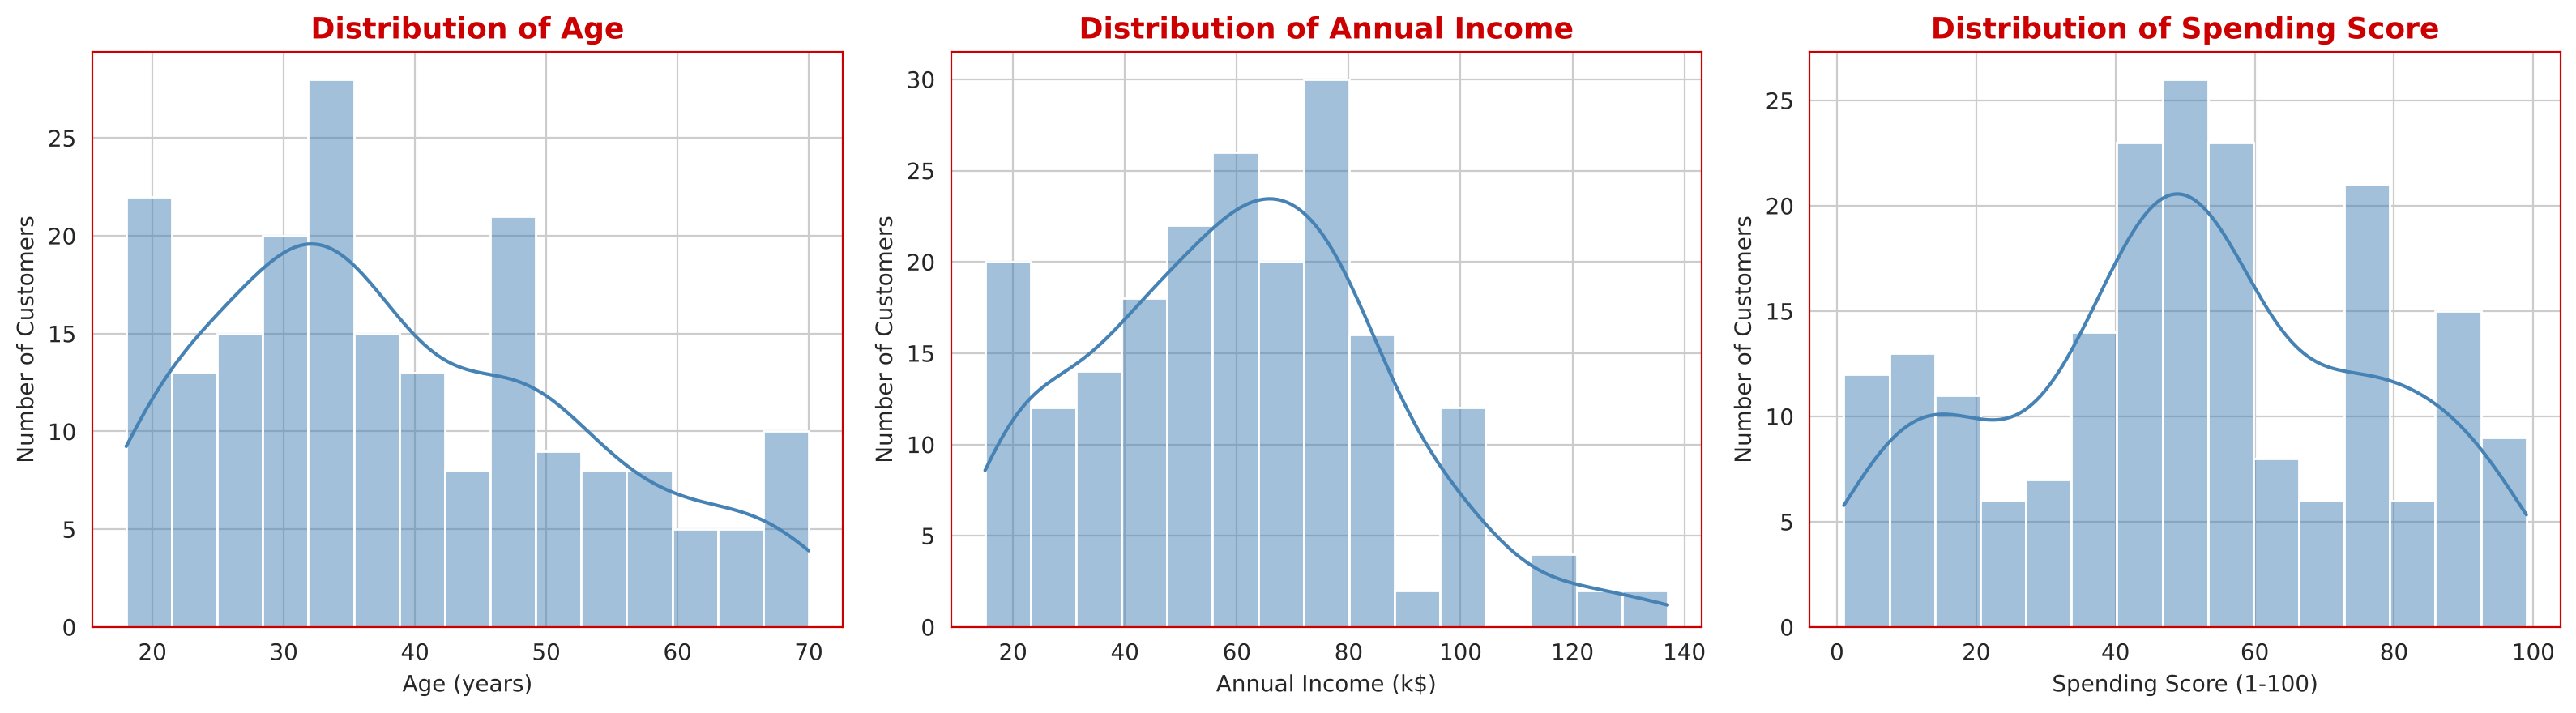

In [8]:
# ─── 1.4 Har feature ka distribution — histogram + KDE curve ───
plt.figure(figsize=(16, 4.5))

plt.subplot(1, 3, 1)
sns.histplot(df['Age'], bins=15, kde=True, color='steelblue')
plt.title('Distribution of Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Customers')

plt.subplot(1, 3, 2)
sns.histplot(df['Annual_Income'], bins=15, kde=True, color='steelblue')
plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')

plt.subplot(1, 3, 3)
sns.histplot(df['Spending_Score'], bins=15, kde=True, color='steelblue')
plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

**What the histograms show:**
- **Age** is skewed to the right — most shoppers are between 20 and 50, and fewer are above 55.
- **Annual Income** (in thousands of dollars) is concentrated between ~40 and ~80, with a thin tail above 100.
- **Spending Score** has a tall peak in the middle (around 40–60) and smaller groups at both ends — an early hint that customers form separate groups.

### 1.5 Pairplot & correlation heatmap
The pairplot shows every feature against every other feature — the place where natural groups usually become visible. The heatmap puts a number on how strongly each pair is linearly related.

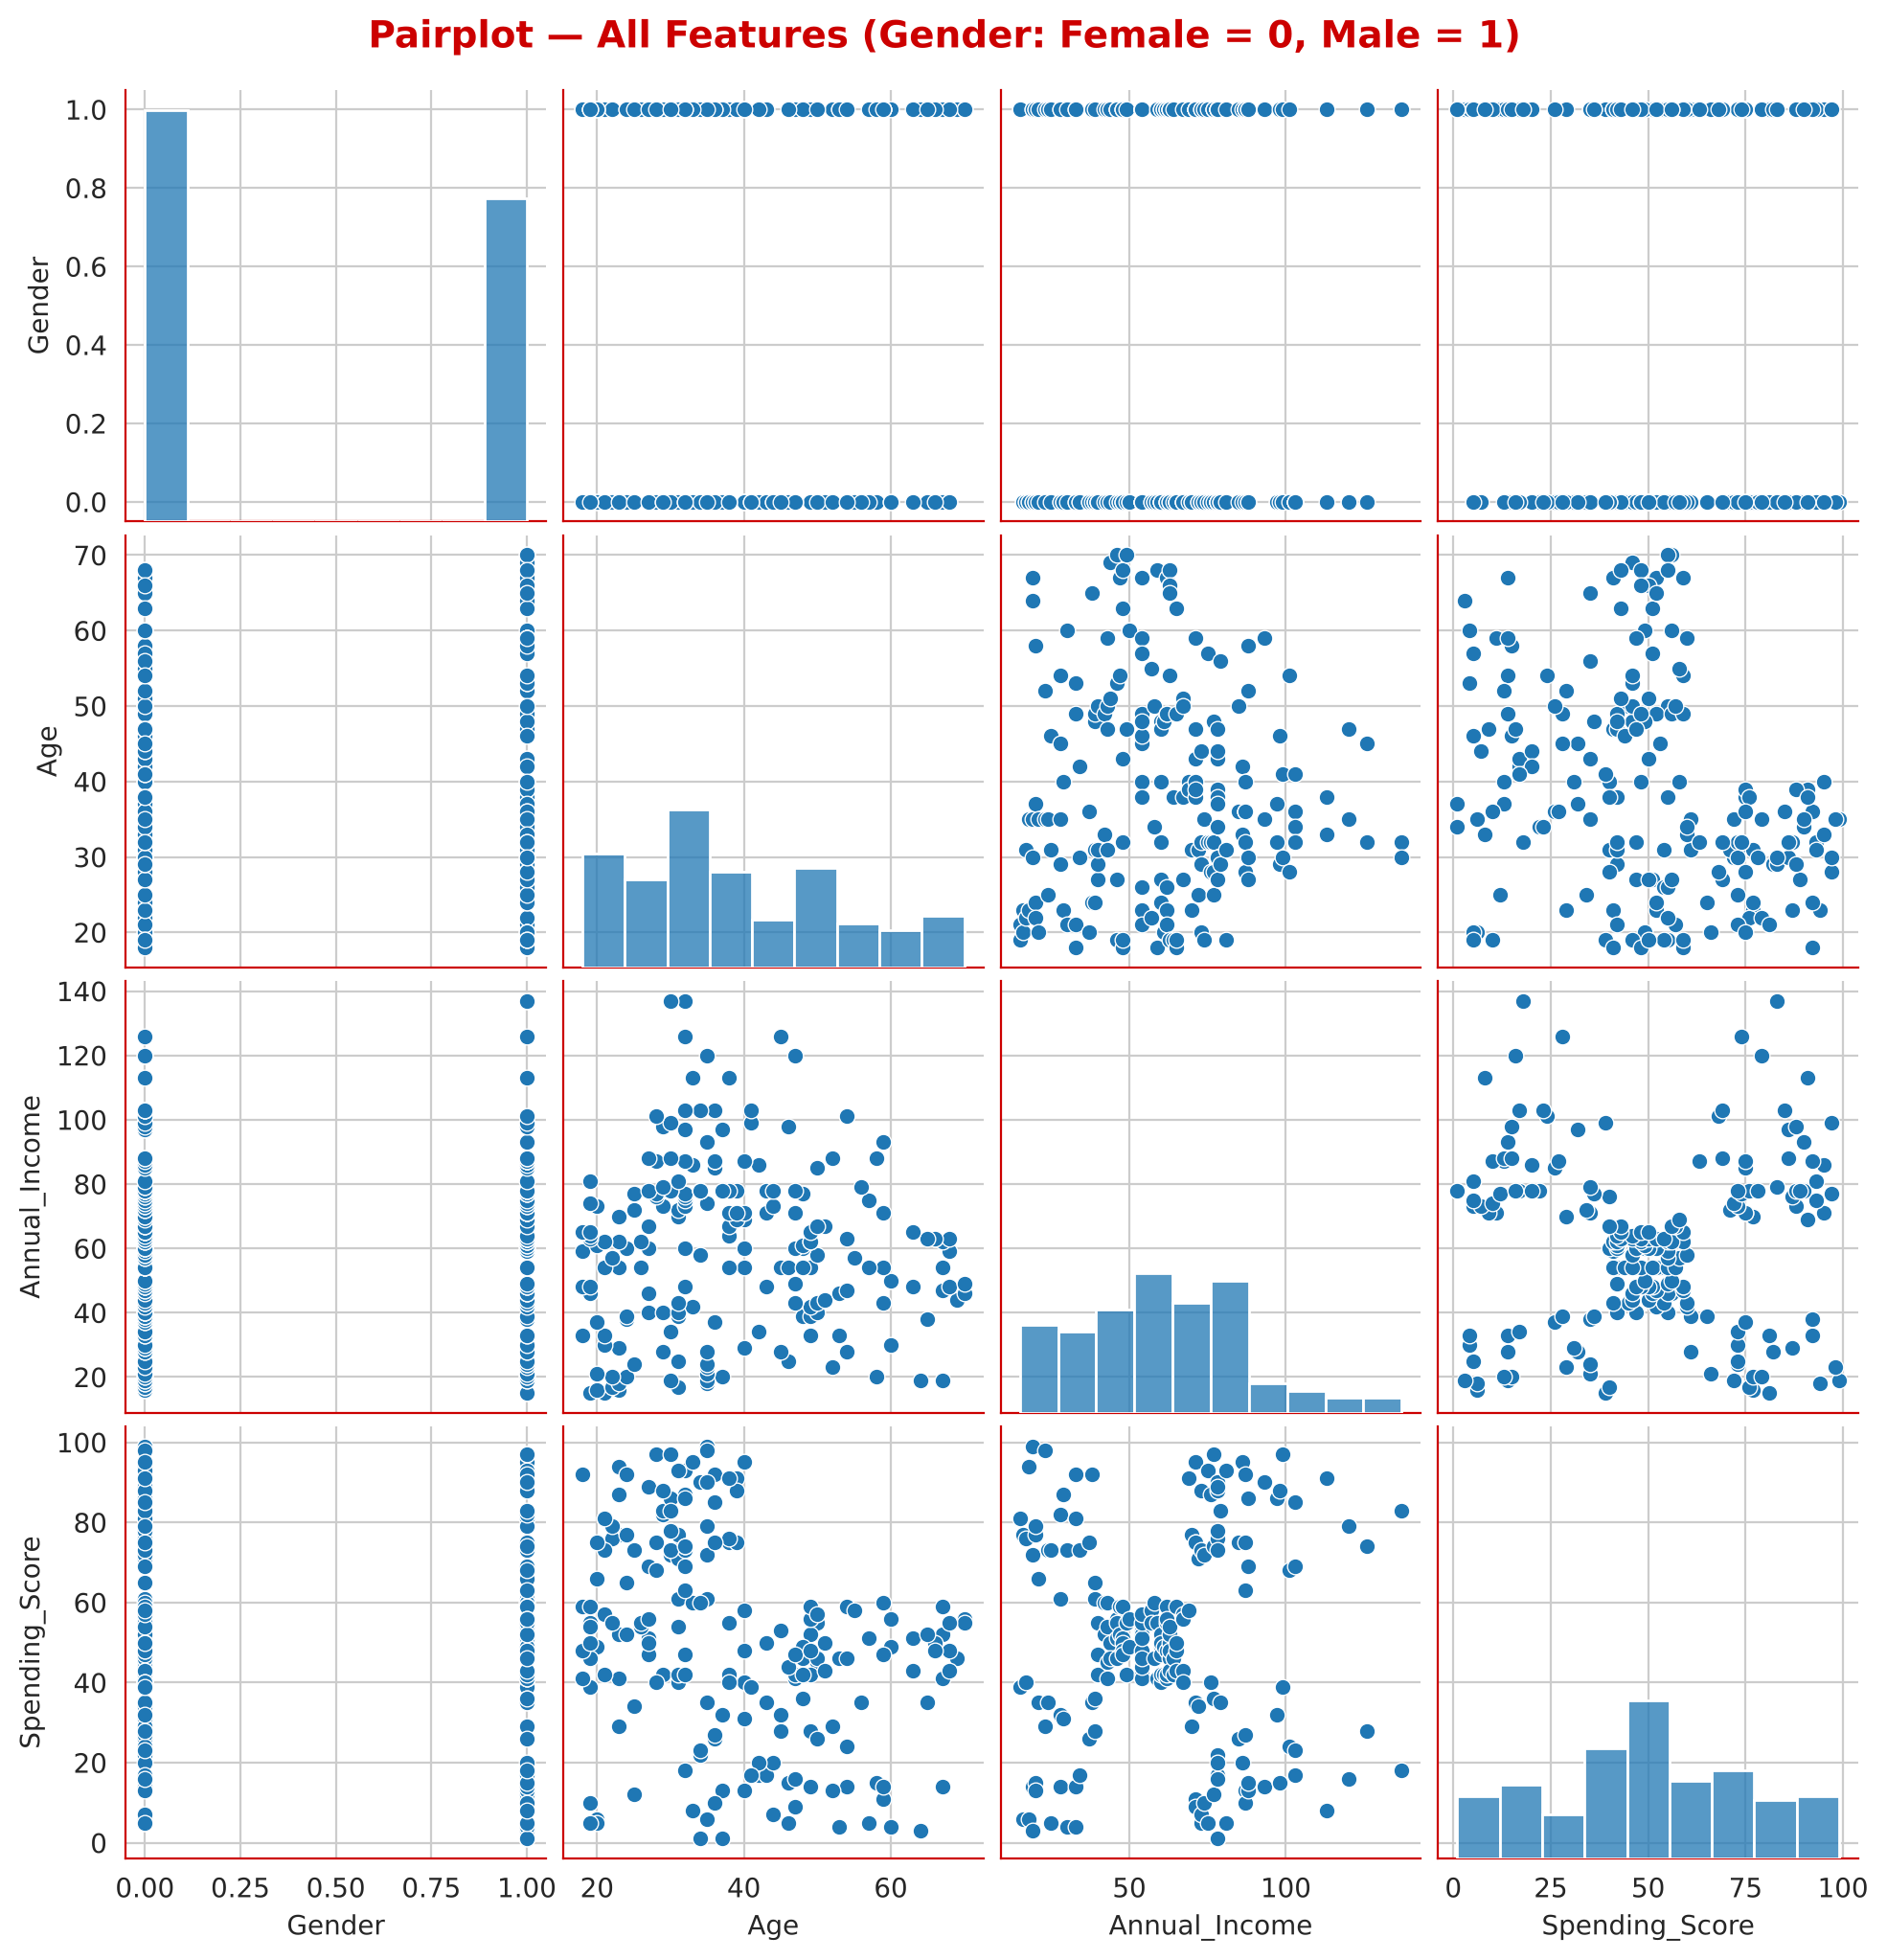

In [9]:
# ─── 1.5 Pairplot — har feature pair ka scatter ───
sns.pairplot(df, hue=None)
plt.suptitle('Pairplot — All Features (Gender: Female = 0, Male = 1)', y=1.02, color=red, fontsize=14, fontweight='bold')
plt.show()

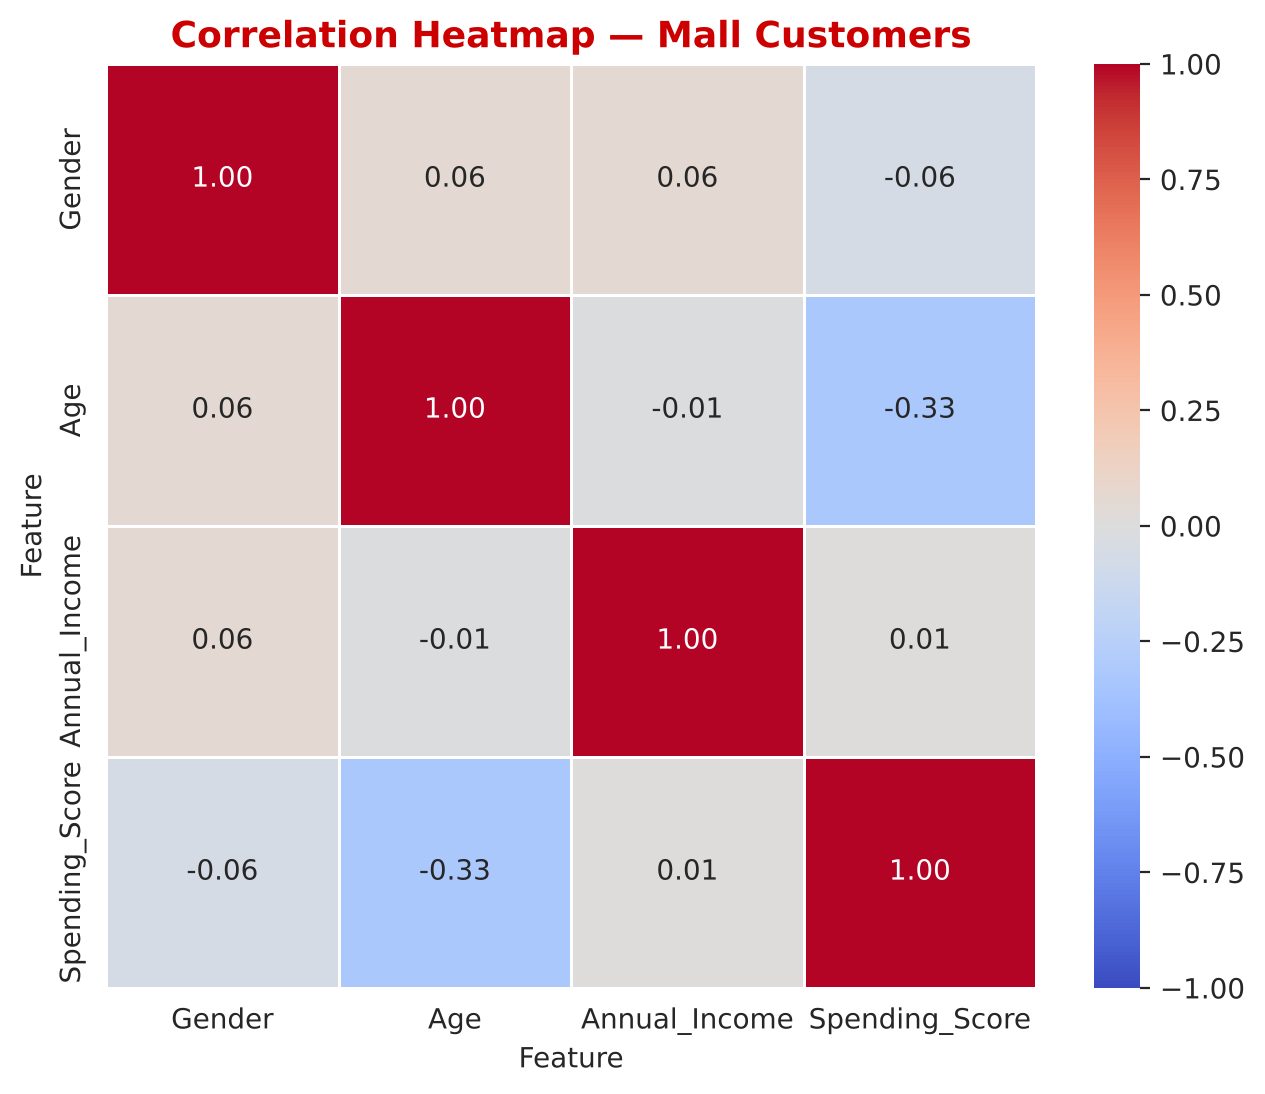

In [10]:
# ─── Correlation heatmap — kaunse features ek-dusre se linked hai ───
plt.figure(figsize=(7.5, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap — Mall Customers')
plt.xlabel('Feature')
plt.ylabel('Feature')
plt.show()

The **Annual_Income vs Spending_Score** panel of the pairplot looks the most interesting, so here it is on its own, bigger — still with no clusters, just raw customers.

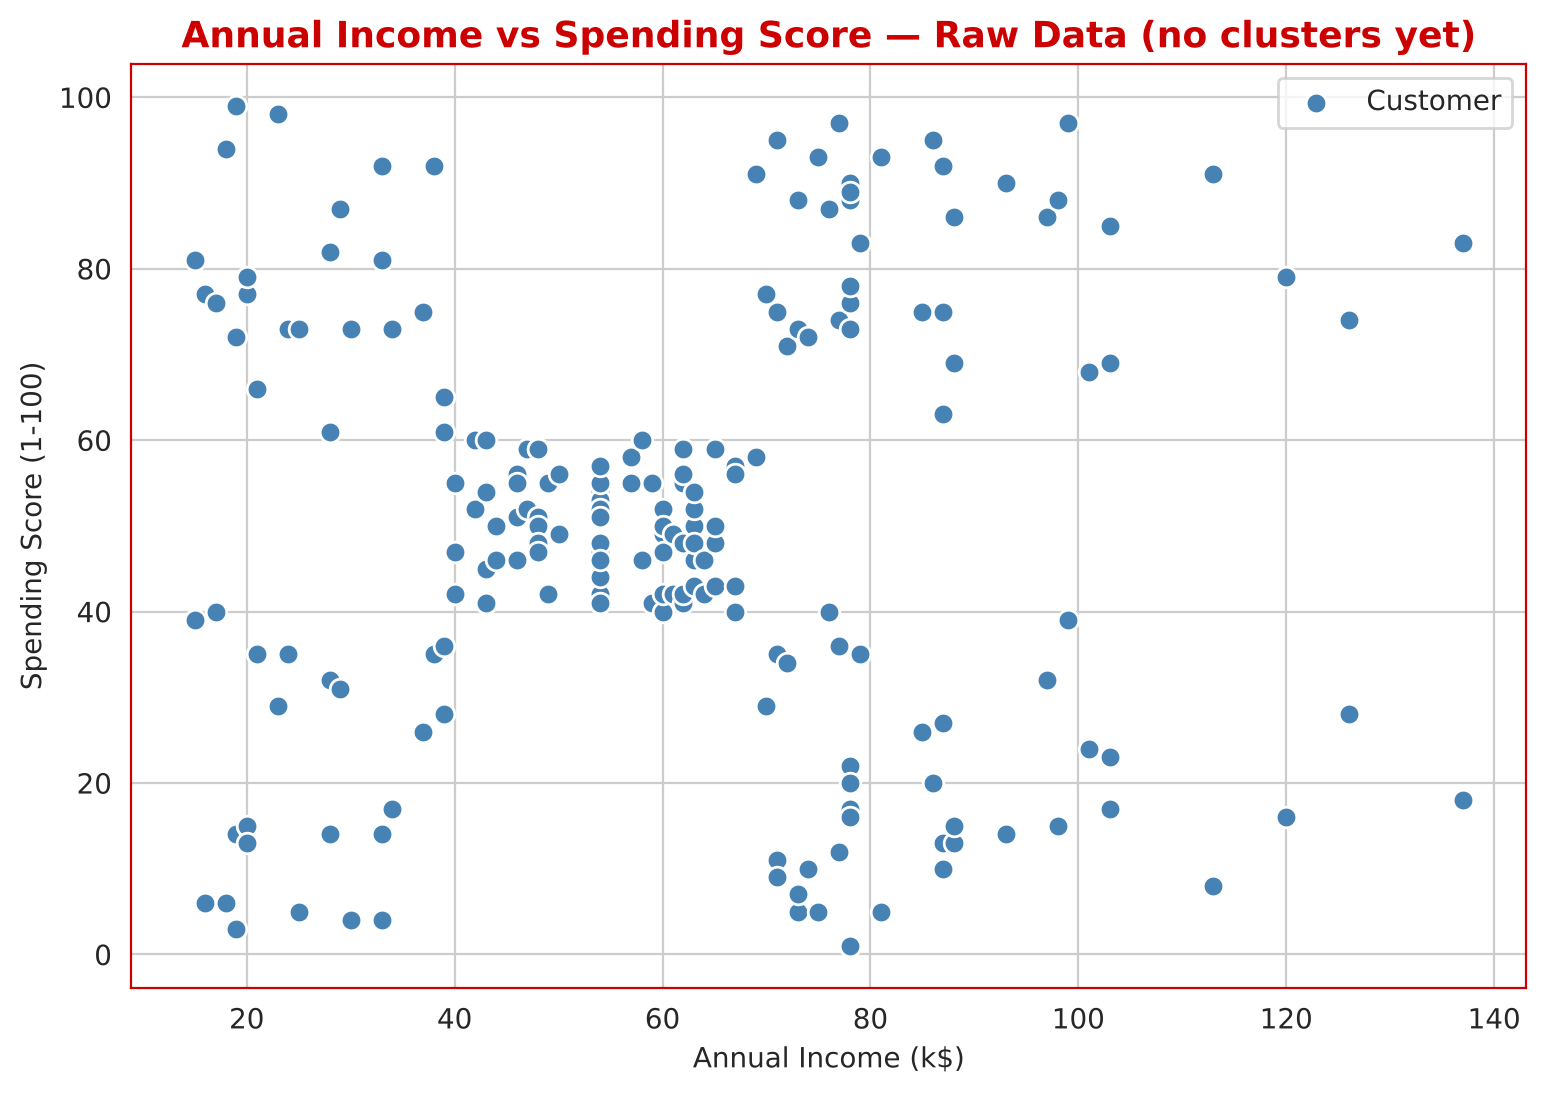

In [11]:
# ─── Pairplot ka sabse interesting panel — bada karke dekhte hai ───
plt.figure(figsize=(9, 6))
plt.scatter(df['Annual_Income'], df['Spending_Score'], s=55, color='steelblue', edgecolor='white', label='Customer')
plt.title('Annual Income vs Spending Score — Raw Data (no clusters yet)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

### 1.6 EDA Summary

- 📌 **The data is clean:** 200 customers, 0 missing values, 0 duplicates — 112 women (56%) and 88 men (44%).
- 📌 **No strong linear links:** the strongest correlation is **Age vs Spending_Score = −0.33** (younger customers tend to spend a little more). **Annual_Income vs Spending_Score is just 0.01** — earning more does *not* automatically mean spending more.
- 📌 **Only one pair shows clear groups:** in the pairplot, **Annual_Income vs Spending_Score** shows about **five separate blobs** — four corners and one big group in the centre. No other pair separates this clearly.
- 📌 **Gender adds almost nothing:** its correlation with every other feature is below 0.07, so it is unlikely to drive the segments.
- 📌 **Feature choice — Annual_Income + Spending_Score:** they are almost uncorrelated (so each brings different information), they are on similar ranges, and together they describe a customer's *ability* to spend and their actual spending *behaviour* — exactly what a mall's marketing team needs to know.

---
## 2️⃣ Task 2: Feature Scaling & Feature Selection

**Objective:** Put Age, Annual_Income and Spending_Score on the same scale, then select the two features used for clustering.

**Expected output:** `df_scaled` (3 standardised columns with mean ≈ 0 and std ≈ 1) and `df_2f` (Annual_Income + Spending_Score, 200 rows × 2 columns).

### 2.1 Scale features

In [12]:
# ─── 2.1 StandardScaler — Age, Income, Spending ko same scale par lao ───
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_values = scaler.fit_transform(df[['Age', 'Annual_Income', 'Spending_Score']])

# Gender ko scale nahi kiya — woh already 0/1 binary hai
df_scaled = pd.DataFrame(scaled_values, columns=['Age', 'Annual_Income', 'Spending_Score'])
df_scaled.head()

,Age,Annual_Income,Spending_Score
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [13]:
# Scaling ke baad har column ka mean ≈ 0 aur std ≈ 1 hona chahiye
df_scaled.describe().round(2)

,Age,Annual_Income,Spending_Score
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


In [14]:
# ─── Verify: StandardScaler ka formula manually check karo ───
# z = (x - mean) / std      (StandardScaler population std use karta hai → ddof=0)
manual_z = (df['Annual_Income'] - df['Annual_Income'].mean()) / df['Annual_Income'].std(ddof=0)

print('Method 1 (manual formula) :', manual_z.head(3).round(4).tolist())
print('Method 2 (StandardScaler) :', df_scaled['Annual_Income'].head(3).round(4).tolist())

Method 1 (manual formula) : [-1.739, -1.739, -1.7008]
Method 2 (StandardScaler) : [-1.739, -1.739, -1.7008]


Both methods give the same numbers — StandardScaler is just **z = (x − mean) / std** applied to every column.

### 2.2 Select 2-feature subset

In [15]:
# ─── 2.2 Clustering ke liye 2 features select karo ───
df_2f = df_scaled[['Annual_Income', 'Spending_Score']]

print('df_2f shape:', df_2f.shape)
df_2f.head()

df_2f shape: (200, 2)


,Annual_Income,Spending_Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


📌 **Why only 2 features?** Annual_Income and Spending_Score showed the clearest groups in the EDA, and with just 2 features every clustering result can be drawn directly as a 2D scatter plot — no PCA needed. Using all 4 features is also valid, so I test that in the **Task 6 Extension**, but the main tasks use `df_2f` for visual clarity.

### 2.3 Why scaling is required before clustering

K-Means, Hierarchical clustering and DBSCAN all decide who is "close" to whom using **distance** — usually the Euclidean distance:

$$d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$

If one feature is measured in bigger numbers, its differences are bigger numbers too, so it quietly controls the distance — and therefore the clusters — even though it is not more important. **StandardScaler** fixes this with **z = (x − mean) / std**: every feature gets mean 0 and standard deviation 1, so every feature gets an equal vote.

In this dataset, Annual_Income's raw range (15–137, about 122 points) is wider than Spending_Score's (1–99, about 98 points), so without scaling income would get extra weight in every distance calculation.

📌 **What I noticed:** for *these two* features the effect is actually small — their spreads are almost equal (std ≈ 26.3 vs 25.8). The difference becomes big as soon as other features join: Age has a much smaller spread (std ≈ 14.0), and real-world income is often in raw rupees (lakhs), which would completely drown out a 1–100 score. So scaling is the right habit every time — and it becomes essential in the Task 6 Extension, where Age and Gender are added.

---
## 3️⃣ Task 3: K-Means Clustering

**Objective:** Find the best number of clusters with the Elbow Method and the Silhouette Score, then group the customers with K-Means.

**Expected output:** an Elbow plot (k = 1–10), a Silhouette plot (k = 2–10), a scatter plot with 5 labelled clusters and black X centroids, and a styled cluster profile table with segment names.

### 3.1 Elbow Method

In [16]:
# ─── 3.1 Elbow Method — k = 1 se 10 tak inertia nikalo ───
from sklearn.cluster import KMeans

inertia = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(df_2f)
    inertia.append(km.inertia_)

# k badhane par inertia hamesha girta hai — dekhna hai girna kahan slow hota hai
for i in range(len(inertia)):
    if i == 0:
        print(f'k = {i + 1:2d}  →  inertia = {inertia[i]:7.2f}')
    else:
        print(f'k = {i + 1:2d}  →  inertia = {inertia[i]:7.2f}   (drop = {inertia[i - 1] - inertia[i]:6.2f})')

k =  1  →  inertia =  400.00
k =  2  →  inertia =  269.69   (drop = 130.31)
k =  3  →  inertia =  157.70   (drop = 111.99)
k =  4  →  inertia =  108.92   (drop =  48.78)
k =  5  →  inertia =   65.57   (drop =  43.35)
k =  6  →  inertia =   55.06   (drop =  10.51)
k =  7  →  inertia =   44.86   (drop =  10.19)
k =  8  →  inertia =   37.23   (drop =   7.64)
k =  9  →  inertia =   32.39   (drop =   4.84)
k = 10  →  inertia =   29.98   (drop =   2.41)


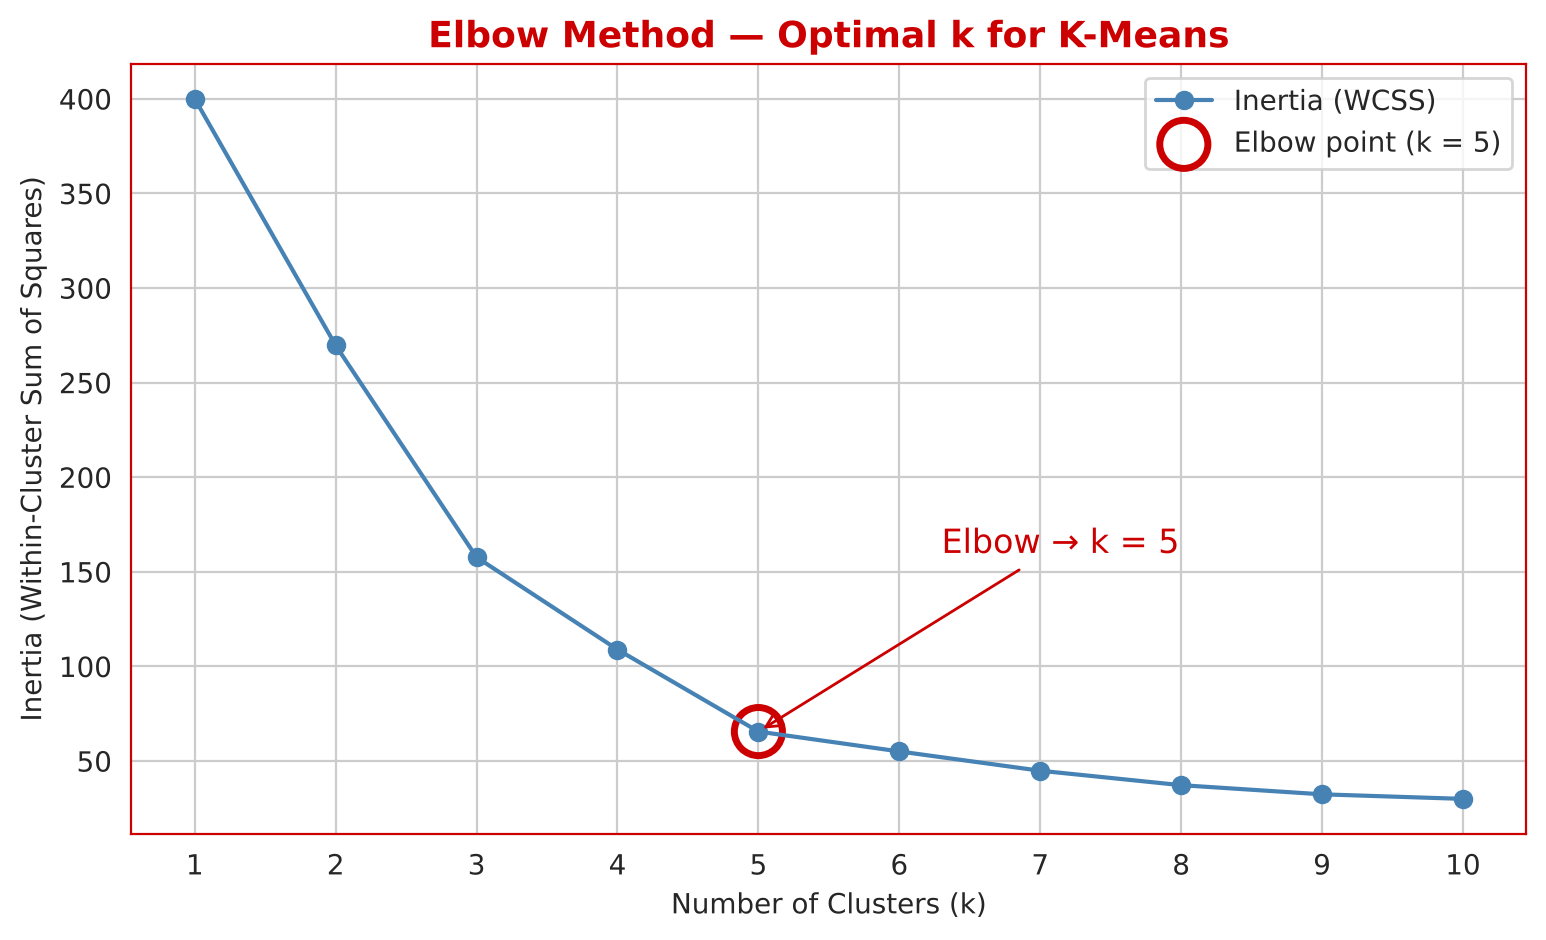

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertia, marker='o', color='steelblue', label='Inertia (WCSS)')

# Elbow point mark karo — k = 5 ke baad curve flat ho jata hai
plt.scatter(5, inertia[4], s=300, facecolors='none', edgecolors=red, linewidths=2.5, label='Elbow point (k = 5)')
plt.annotate('Elbow → k = 5', xy=(5, inertia[4]), xytext=(6.3, 160),
             arrowprops=dict(arrowstyle='->', color=red), color=red, fontsize=12)

plt.title('Elbow Method — Optimal k for K-Means')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(k_values)
plt.legend()
plt.show()

📌 **What inertia measures:** inertia (also called WCSS) is the sum of squared distances from every customer to the centroid of their own cluster. Lower inertia = tighter, more compact clusters.

📌 **Why the elbow gives a good k:** inertia *always* goes down when k goes up — with k = 200 every customer would be its own cluster and inertia would be 0, which is useless. So the question is: where does adding one more cluster stop paying off? Here the drops are big up to k = 5 (**130 → 112 → 49 → 43**) and then suddenly small (**10.5, 10.2, 7.6 …**). That bend in the curve is the **elbow at k = 5**.

### 3.2 Silhouette Score

In [18]:
# ─── 3.2 Silhouette Score — k = 2 se 10 ───
from sklearn.metrics import silhouette_score

sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(df_2f)
    sil_scores.append(silhouette_score(df_2f, labels))

for k, s in zip(k_range, sil_scores):
    print(f'k = {k:2d}  →  silhouette = {s:.4f}')

best_k = k_range[sil_scores.index(max(sil_scores))]
print('\nBest k by Silhouette Score:', best_k)

k =  2  →  silhouette = 0.3213
k =  3  →  silhouette = 0.4666
k =  4  →  silhouette = 0.4939
k =  5  →  silhouette = 0.5547
k =  6  →  silhouette = 0.5399
k =  7  →  silhouette = 0.5281
k =  8  →  silhouette = 0.4552
k =  9  →  silhouette = 0.4571
k = 10  →  silhouette = 0.4432

Best k by Silhouette Score: 5


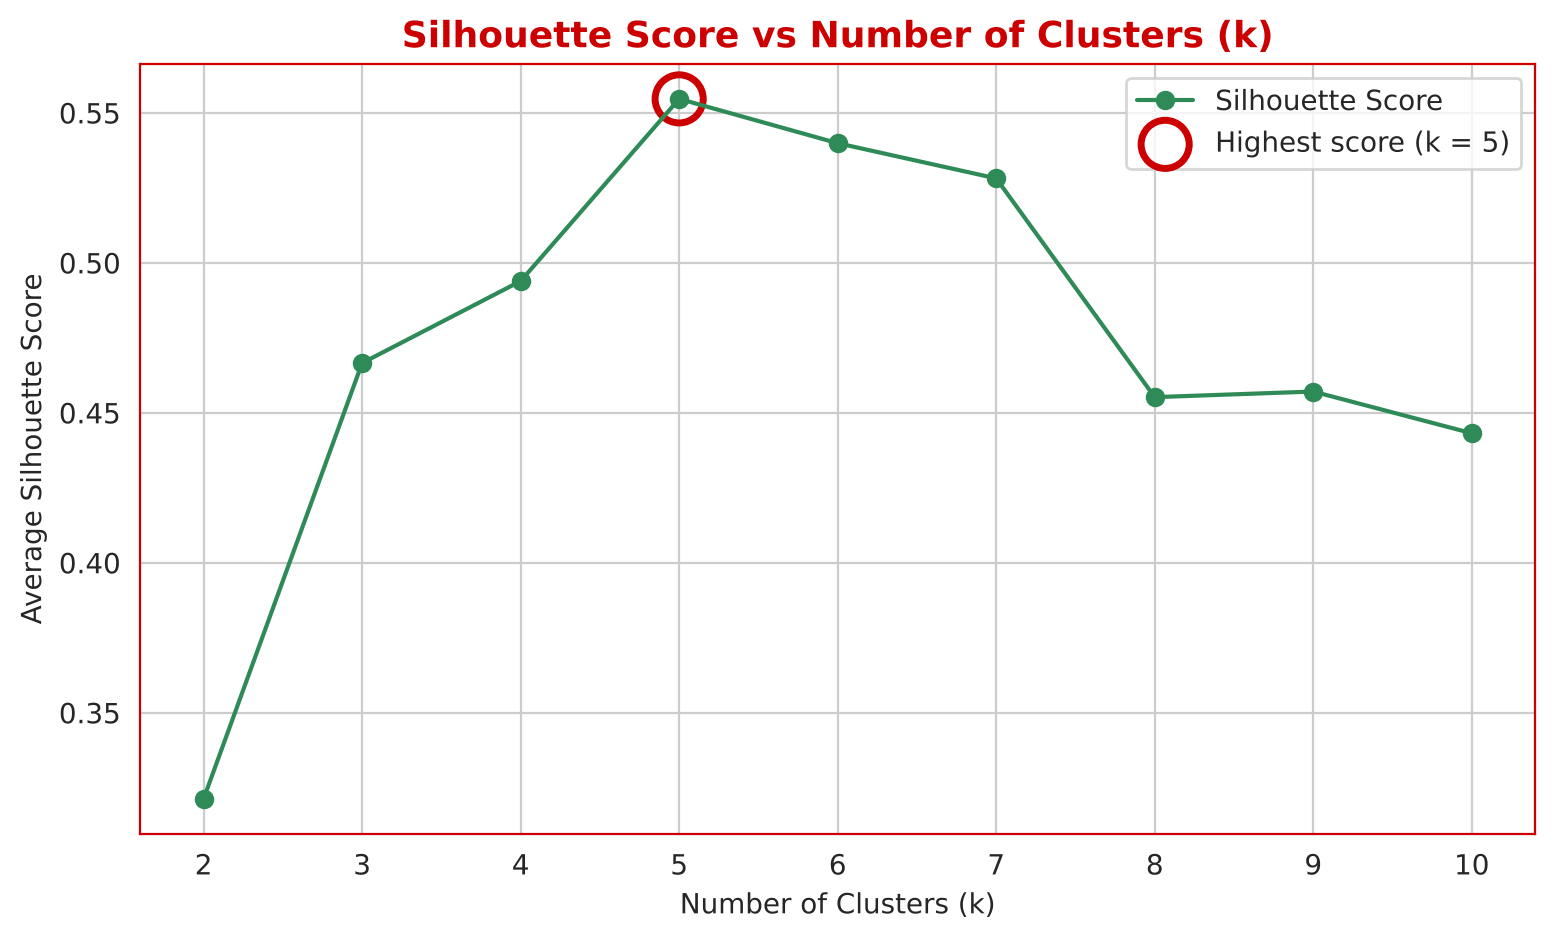

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(k_range, sil_scores, marker='o', color='seagreen', label='Silhouette Score')
plt.scatter(best_k, max(sil_scores), s=300, facecolors='none', edgecolors=red, linewidths=2.5,
            label=f'Highest score (k = {best_k})')
plt.title('Silhouette Score vs Number of Clusters (k)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_range)
plt.legend()
plt.show()

📌 **What the Silhouette Score checks:** for every customer it compares *a* = average distance to their own cluster and *b* = average distance to the nearest other cluster: **s = (b − a) / max(a, b)**. It ranges from −1 to 1, and higher means compact *and* well-separated clusters.

📌 **Result:** the highest score is **0.5547 at k = 5** — the data-driven optimum.

📌 **Elbow vs Silhouette — do they agree?** Yes, both point to **k = 5**, so there is no conflict to resolve here. They *can* disagree, because the Elbow only looks at compactness (inertia), while Silhouette also rewards separation between clusters. k = 6 (0.540) comes close, but it doesn't beat k = 5 — and fewer segments are easier for a marketing team to act on. **Final choice: k = 5.**

### 3.3 Fit final K-Means model

In [20]:
# ─── 3.3 Final K-Means model — k = 5 ───
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(df_2f)

print(df['KMeans_Cluster'].value_counts().sort_index())
df.head()

KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,Gender,Age,Annual_Income,Spending_Score,KMeans_Cluster
0,1,19,15,39,4
1,1,21,15,81,2
2,0,20,16,6,4
3,0,23,16,77,2
4,0,31,17,40,4


### 3.4 Visualise K-Means clusters

⚠️ **A small but important fix before plotting:** the model was trained on **scaled** data, so `kmeans.cluster_centers_` are in scaled units (roughly −1.3 to +1.3). The scatter plot uses the **original** income and spending values (15–137 and 1–99). Plotting the raw centres there would drop every X into the bottom-left corner, far away from its cluster.

A centroid is simply the **mean of its cluster's points** — that's the "Means" in K-Means. So the centroids for the plot are each cluster's average income and spending in original units. First, a quick check that this "mean" logic really matches what K-Means calculated:

In [21]:
# ─── Verify: centroid = cluster ka mean ───
# Method 1: scaled data mein har cluster ka mean manually
manual_centers = df_2f.groupby(df['KMeans_Cluster']).mean()
print('Method 1 — manual cluster means (scaled):')
print(manual_centers.values.round(4))

# Method 2: K-Means ke apne centroids
print('\nMethod 2 — kmeans.cluster_centers_ (scaled):')
print(kmeans.cluster_centers_.round(4))

Method 1 — manual cluster means (scaled):
[[-0.2009 -0.0265]
 [ 0.9916  1.2395]
 [-1.3295  1.1322]
 [ 1.055  -1.2844]
 [-1.3075 -1.137 ]]

Method 2 — kmeans.cluster_centers_ (scaled):
[[-0.2009 -0.0265]
 [ 0.9916  1.2395]
 [-1.3295  1.1322]
 [ 1.055  -1.2844]
 [-1.3075 -1.137 ]]


In [22]:
# Same logic — original units mein centroids (plot ke liye)
centroids = df.groupby('KMeans_Cluster')[['Annual_Income', 'Spending_Score']].mean()
centroids.round(1)

,Annual_Income,Spending_Score
KMeans_Cluster,,
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


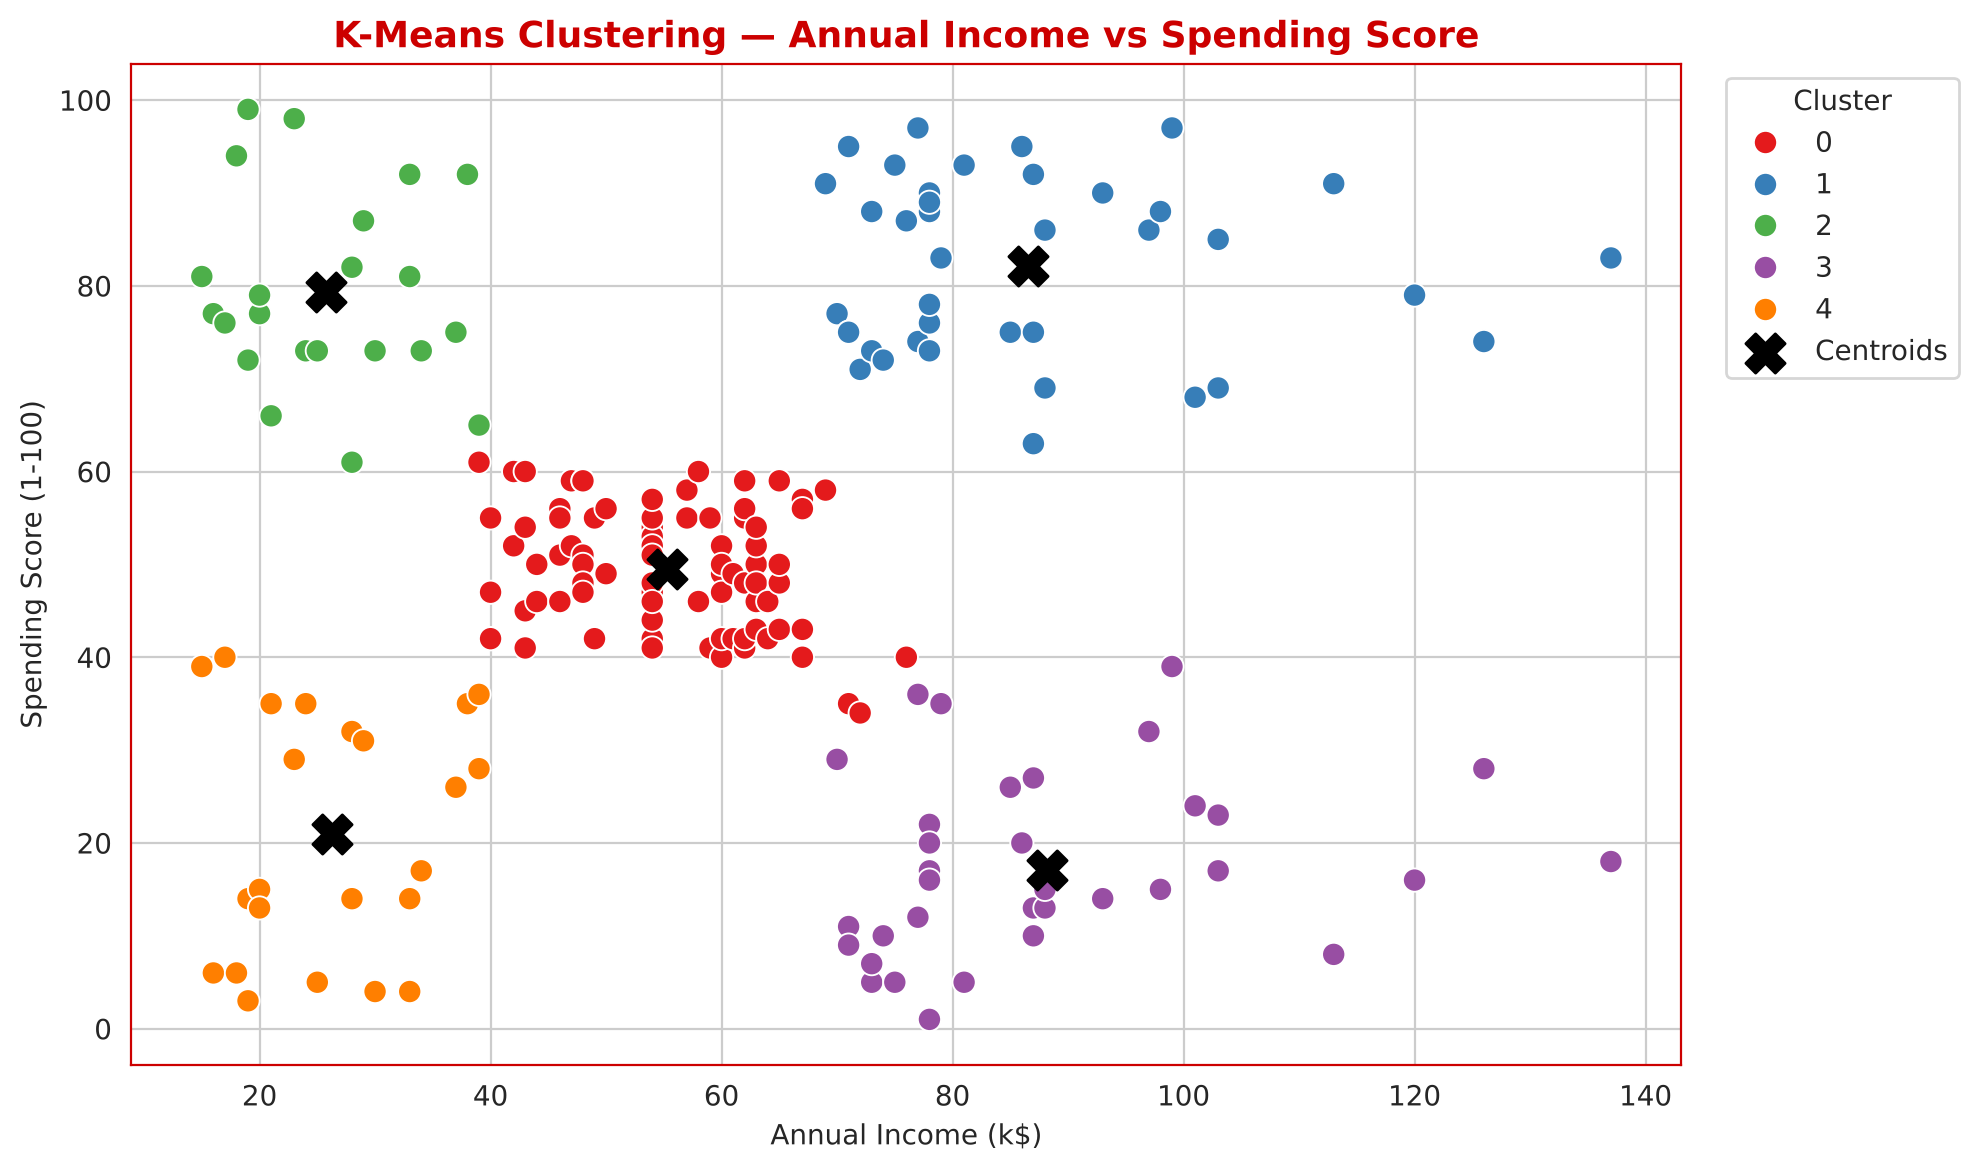

In [23]:
# ─── 3.4 K-Means clusters ka scatter plot ───
plt.figure(figsize=(10, 6.5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=df, palette='Set1', s=70)

# Centroids — black X
plt.scatter(centroids['Annual_Income'], centroids['Spending_Score'], c='black', marker='X', s=200, label='Centroids')

plt.title('K-Means Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### 3.5 Cluster profile table
The cluster numbers (0–4) mean nothing on their own, so each cluster gets a name based on its **average income and spending**. The same naming rule will be used for all three algorithms, so a small helper function keeps it in one place.

In [24]:
# ─── 3.5 Cluster profile — har cluster ka "average customer" ───
kmeans_profile = df.groupby('KMeans_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
kmeans_profile['Customers'] = df.groupby('KMeans_Cluster').size()


# Naming rule — teeno algorithms par same rule lagana hai, isliye ek chhota function
# Income : < 40 → Low,  > 70 → High,  beech mein → Average
# Spending: < 40 → Low,  > 60 → High,  beech mein → Average
def get_segment_name(income, spending):
    if income < 40:
        income_level = 'Low Income'
    elif income > 70:
        income_level = 'High Income'
    else:
        income_level = 'Average Income'

    if spending < 40:
        spending_level = 'Low Spenders'
    elif spending > 60:
        spending_level = 'High Spenders'
    else:
        spending_level = 'Average Spenders'

    return income_level + ', ' + spending_level


kmeans_names = {}
for c in kmeans_profile.index:
    kmeans_names[c] = get_segment_name(kmeans_profile.loc[c, 'Annual_Income'], kmeans_profile.loc[c, 'Spending_Score'])

kmeans_profile['Segment'] = kmeans_profile.index.map(kmeans_names)
df['KMeans_Segment'] = df['KMeans_Cluster'].map(kmeans_names)

kmeans_profile.style.background_gradient(cmap='Reds', subset=['Annual_Income', 'Spending_Score']).format(precision=1)

,Age,Annual_Income,Spending_Score,Customers,Segment
KMeans_Cluster,,,,,
0,42.7,55.3,49.5,81,"Average Income, Average Spenders"
1,32.7,86.5,82.1,39,"High Income, High Spenders"
2,25.3,25.7,79.4,22,"Low Income, High Spenders"
3,41.1,88.2,17.1,35,"High Income, Low Spenders"
4,45.2,26.3,20.9,23,"Low Income, Low Spenders"


**Segment names & business meaning (K-Means, k = 5)**

| Segment | Customers | Avg Age | Who they are — and what it means for the mall |
|---|---|---|---|
| 💎 **High Income, High Spenders** | 39 (19.5%) | ~33 | Affluent shoppers who spend freely — the mall's most valuable customers. Losing them hurts the most. |
| 🧐 **High Income, Low Spenders** | 35 (17.5%) | ~41 | They *can* spend but don't — careful, value-driven, possibly shopping elsewhere. The biggest untapped opportunity. |
| 🧺 **Average Income, Average Spenders** | 81 (40.5%) | ~43 | The steady core — the largest group by far. Reliable everyday footfall. |
| 🔥 **Low Income, High Spenders** | 22 (11%) | ~25 | The youngest group, spending well beyond their income — trend-driven and quick to respond to offers. |
| 💰 **Low Income, Low Spenders** | 23 (11.5%) | ~45 | Budget-conscious and price-sensitive — they come for essentials and discounts. |

---
## 4️⃣ Task 4: Agglomerative Hierarchical Clustering

**Objective:** Build a bottom-up tree of clusters with Ward linkage, pick the number of clusters from the dendrogram, and compare the result with K-Means.

**Expected output:** a Ward dendrogram with a dashed cut line, a scatter plot with 5 hierarchical clusters, a side-by-side K-Means vs Hierarchical figure, and a hierarchical profile table compared with the K-Means profiles.

### 4.1 Dendrogram

In [25]:
# ─── 4.1 Ward linkage — poora merge history ───
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(df_2f, method='ward')

# Sabse upar ke merges ki heights — inke beech ka sabse bada gap = best cut
top_heights = linked[-6:, 2][::-1]
print('Top 6 merge heights (highest first):', top_heights.round(2))
print()
for i in range(len(top_heights) - 1):
    print(f'Cut between {top_heights[i + 1]:5.2f} and {top_heights[i]:5.2f}  →  {i + 2} clusters   (gap = {top_heights[i] - top_heights[i + 1]:.2f})')

Top 6 merge heights (highest first): [15.62 15.19 10.14  9.45  4.35  4.31]

Cut between 15.19 and 15.62  →  2 clusters   (gap = 0.44)
Cut between 10.14 and 15.19  →  3 clusters   (gap = 5.04)
Cut between  9.45 and 10.14  →  4 clusters   (gap = 0.69)
Cut between  4.35 and  9.45  →  5 clusters   (gap = 5.10)
Cut between  4.31 and  4.35  →  6 clusters   (gap = 0.05)


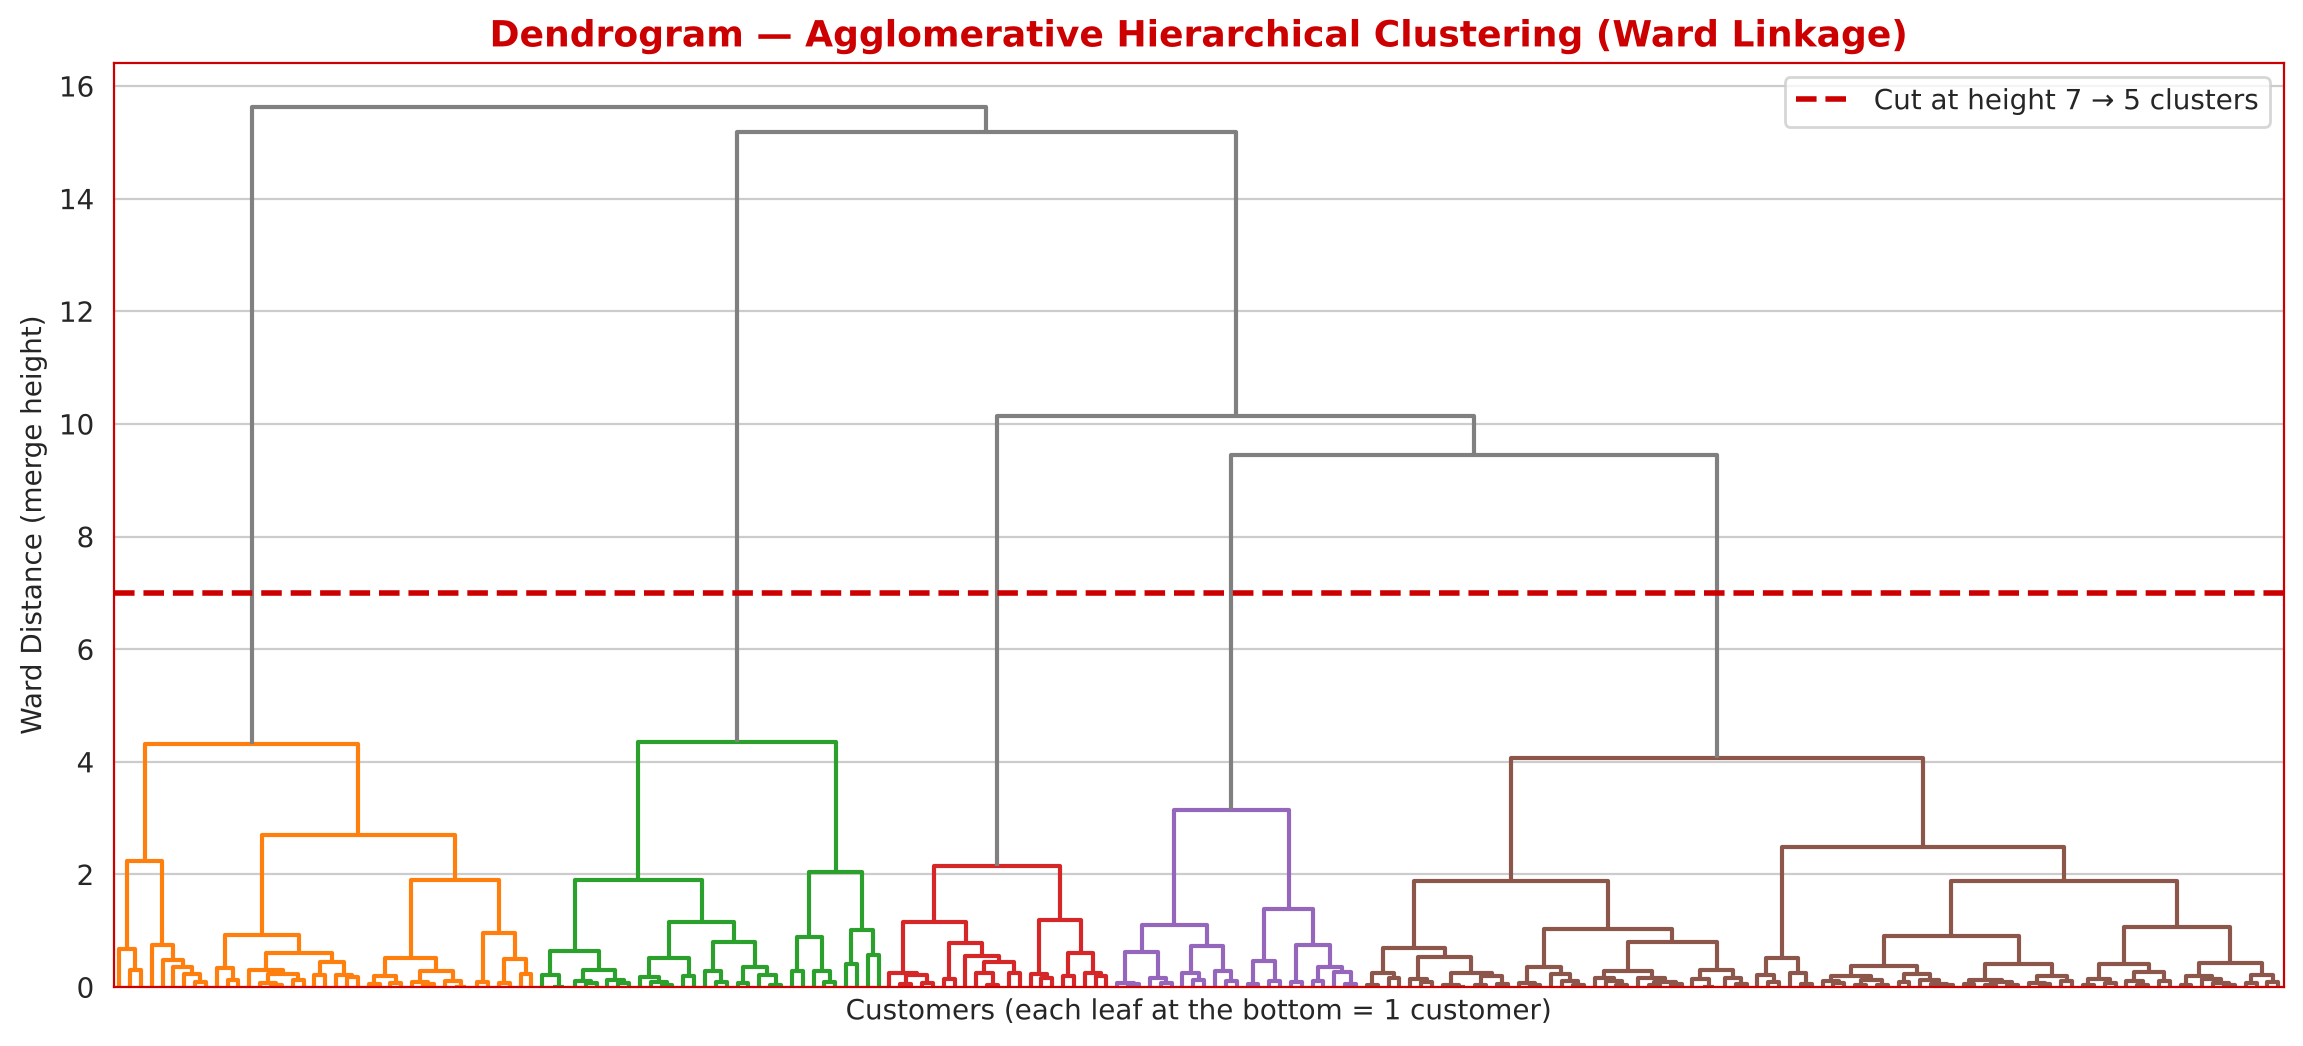

In [26]:
# ─── Dendrogram + cut line ───
plt.figure(figsize=(14, 6))
dendrogram(linked, no_labels=True, color_threshold=7, above_threshold_color='gray')
plt.axhline(y=7, color=red, linestyle='--', linewidth=2, label='Cut at height 7 → 5 clusters')
plt.title('Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Customers (each leaf at the bottom = 1 customer)')
plt.ylabel('Ward Distance (merge height)')
plt.legend()
plt.show()

📌 **How to read a dendrogram:** every customer starts at the bottom as their own cluster. Each ∩-shaped join is a merge, and the **height** of the join shows how different the two merged groups were. Short joins near the bottom = very similar customers. Tall joins at the top = very different groups being forced together.

📌 **Choosing the number of clusters:** look for the **longest vertical lines** — the biggest jump between one merge and the next — and cut through them with a horizontal line. The biggest gap is between heights **4.35 and 9.45 (gap = 5.10)**, so the cut at **7** crosses **5 branches → 5 clusters** (the 5 colours below the line). The gap for 3 clusters (5.04) is almost as big, but 5 is slightly bigger *and* agrees with both the Elbow and the Silhouette results from Task 3.

📌 **What Ward linkage minimises:** at every step, Ward merges the two clusters whose merge causes the **smallest increase in total within-cluster variance** (the sum of squared distances to each cluster's mean). That's the same quantity K-Means minimises (inertia), which is why Ward tends to build compact, similar-sized, K-Means-like clusters.

### 4.2 Fit Agglomerative model

In [27]:
# ─── 4.2 Agglomerative model — dendrogram ke cut ke hisaab se 5 clusters ───
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
df['Hier_Cluster'] = hier.fit_predict(df_2f)

print(df['Hier_Cluster'].value_counts().sort_index())

Hier_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


### 4.3 Visualise Hierarchical clusters

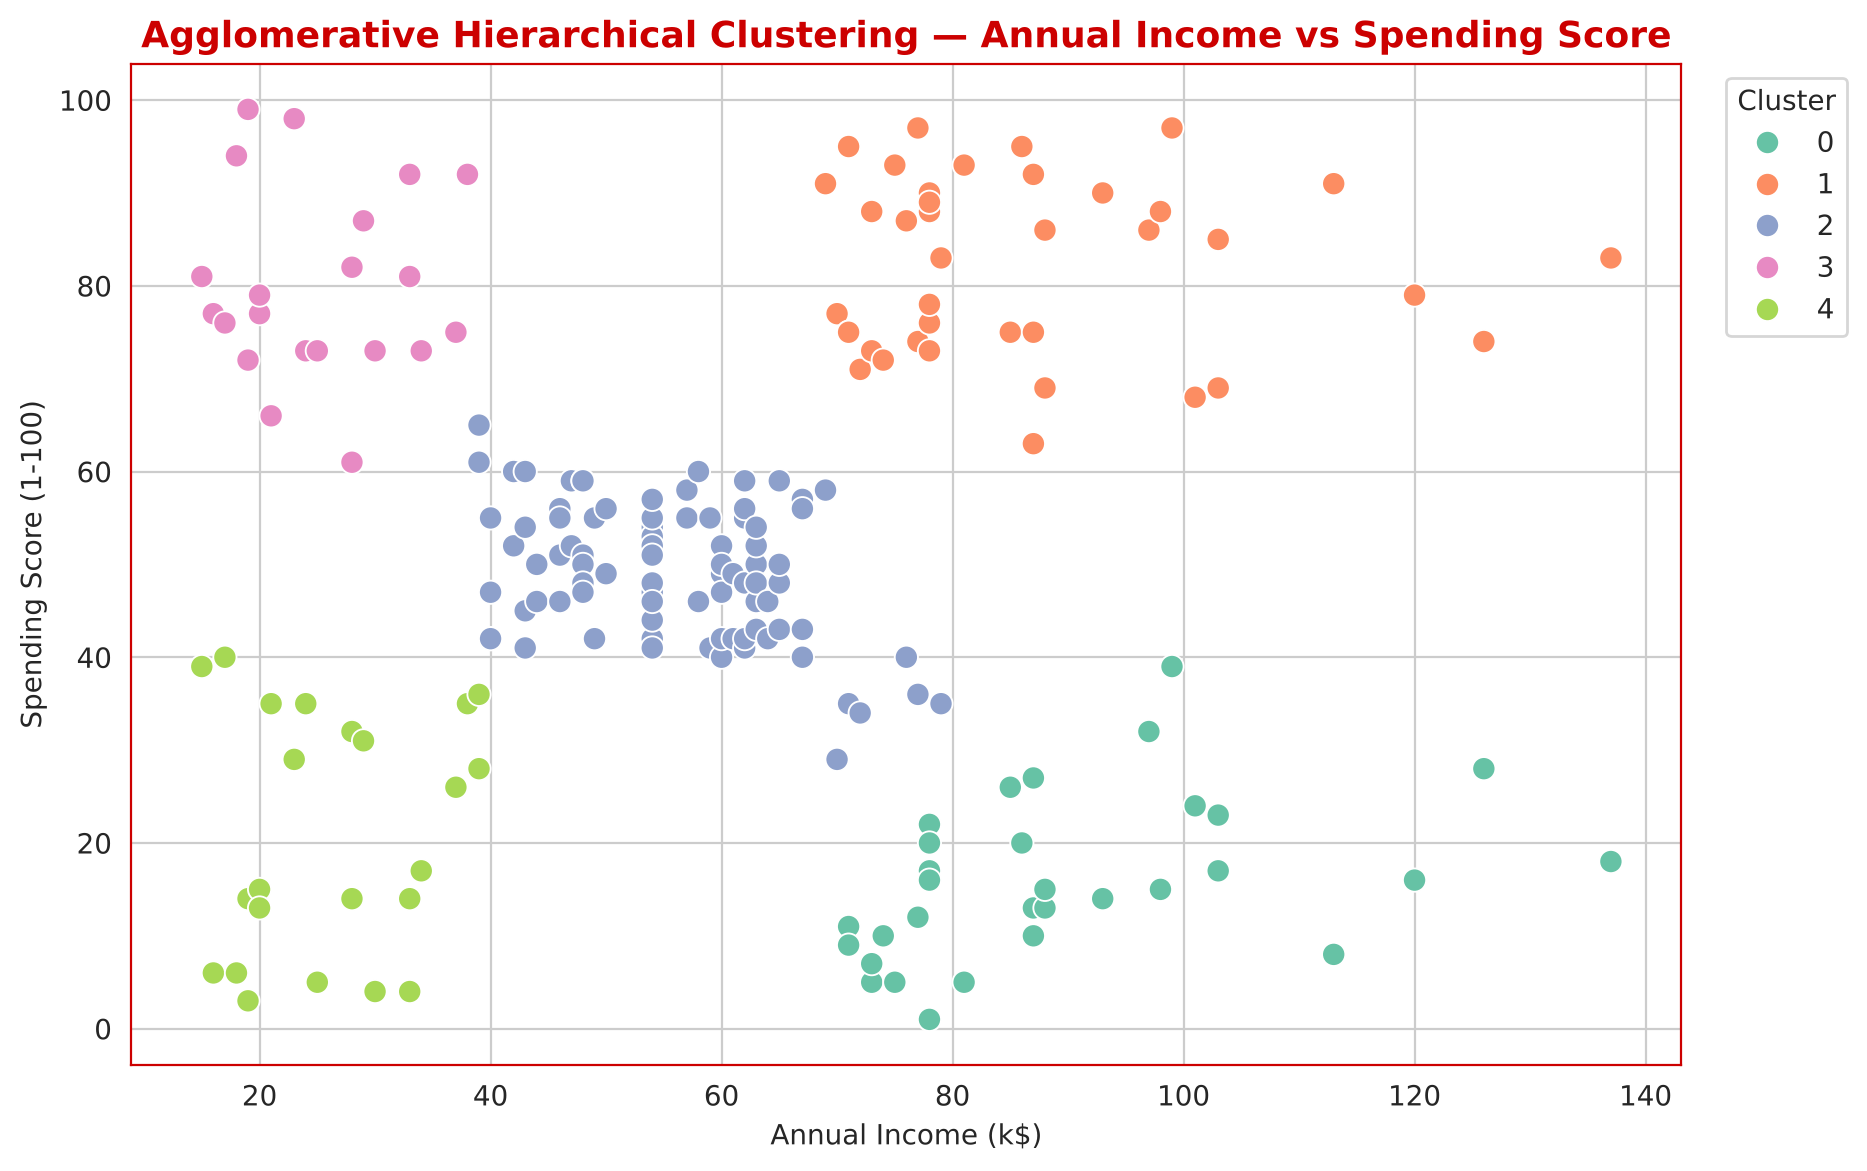

In [28]:
# ─── 4.3 Hierarchical clusters ka scatter plot ───
plt.figure(figsize=(10, 6.5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Cluster', data=df, palette='Set2', s=70)
plt.title('Agglomerative Hierarchical Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### 4.4 Compare with K-Means
Cluster *numbers* from two different algorithms don't match (K-Means' cluster 0 is not Hierarchical's cluster 0), so both are compared through the **segment names** — same rule, same colour for the same segment.

In [29]:
# ─── Hierarchical clusters ko bhi same rule se naam do ───
hier_profile = df.groupby('Hier_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
hier_profile['Customers'] = df.groupby('Hier_Cluster').size()

hier_names = {}
for c in hier_profile.index:
    hier_names[c] = get_segment_name(hier_profile.loc[c, 'Annual_Income'], hier_profile.loc[c, 'Spending_Score'])

hier_profile['Segment'] = hier_profile.index.map(hier_names)
df['Hier_Segment'] = df['Hier_Cluster'].map(hier_names)

# Ek segment = ek colour (4.4 aur 6.1 dono mein)
segment_colors = {
    'High Income, High Spenders':       '#CC0000',
    'High Income, Low Spenders':        '#1f77b4',
    'Average Income, Average Spenders': '#8c8c8c',
    'Low Income, High Spenders':        '#ff7f0e',
    'Low Income, Low Spenders':         '#2ca02c',
}
segment_order = list(segment_colors.keys())

# Jahan dono algorithms ka segment alag hai — woh "border" customers
diff = df[df['KMeans_Segment'] != df['Hier_Segment']]
print('Customers assigned differently:', len(diff), 'out of', len(df))
diff[['Age', 'Annual_Income', 'Spending_Score', 'KMeans_Segment', 'Hier_Segment']]

Customers assigned differently: 4 out of 200


,Age,Annual_Income,Spending_Score,KMeans_Segment,Hier_Segment
45,24,39,65,"Low Income, High Spenders","Average Income, Average Spenders"
124,23,70,29,"High Income, Low Spenders","Average Income, Average Spenders"
146,48,77,36,"High Income, Low Spenders","Average Income, Average Spenders"
160,56,79,35,"High Income, Low Spenders","Average Income, Average Spenders"


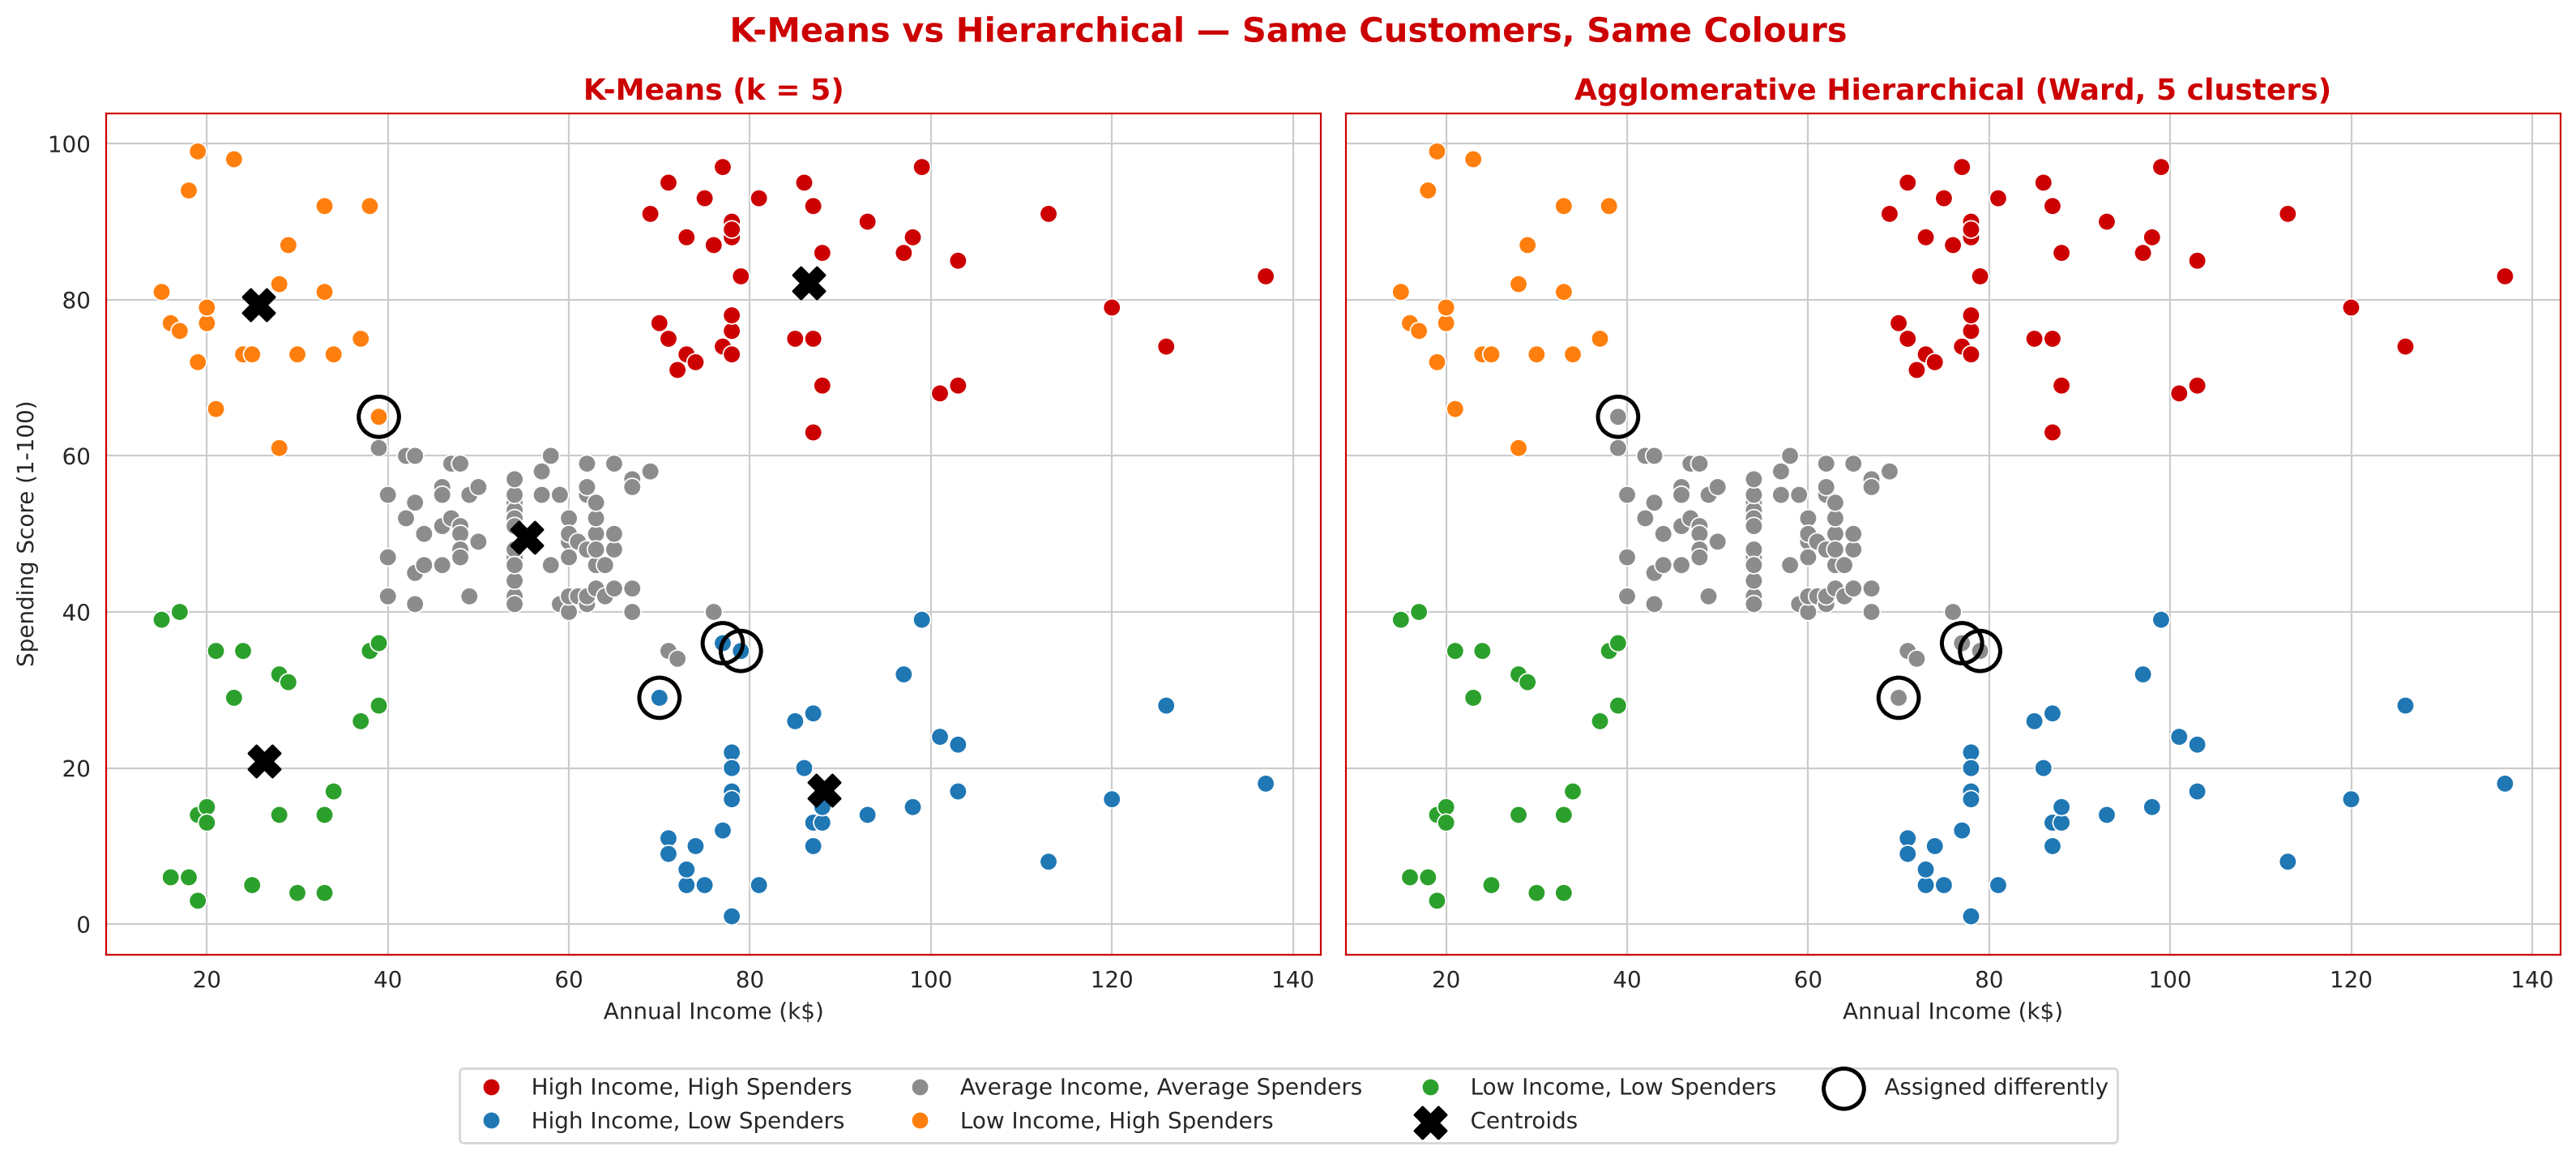

In [30]:
# ─── 4.4 Side-by-side — K-Means (left) vs Hierarchical (right) ───
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Segment', hue_order=segment_order,
                data=df, palette=segment_colors, s=60, ax=axes[0])
axes[0].scatter(centroids['Annual_Income'], centroids['Spending_Score'], c='black', marker='X', s=200, label='Centroids')
axes[0].set_title('K-Means (k = 5)')

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Segment', hue_order=segment_order,
                data=df, palette=segment_colors, s=60, ax=axes[1], legend=False)
axes[1].set_title('Agglomerative Hierarchical (Ward, 5 clusters)')

# Jo customers dono mein alag assign huye — unhe circle karo
for ax in axes:
    ax.scatter(diff['Annual_Income'], diff['Spending_Score'], s=320, facecolors='none',
               edgecolors='black', linewidths=1.8, label='Assigned differently')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

# Ek common legend — figure ke neeche, taaki koi point na chhupe
handles, labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.1), fontsize=10)

fig.suptitle('K-Means vs Hierarchical — Same Customers, Same Colours', color=red, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

📌 **Do the cluster boundaries agree?** Almost completely: **196 of 200 customers (98%)** land in the same segment with both algorithms. *High Income, High Spenders* and *Low Income, Low Spenders* match exactly, customer for customer.

📌 **Which customers were assigned differently, and why?** Only the **4 circled customers** (rows 45, 124, 146 and 160 in the table above). All of them sit on the **border between the big middle group and a corner group** — K-Means put them in the corner segment, Hierarchical put them in the middle one.
- **K-Means is centroid-based.** Every customer simply goes to the *nearest centroid*, so the boundaries are straight lines exactly halfway between two centroids, and points keep getting re-assigned until the centroids stop moving. These 4 customers are slightly closer to a corner centroid.
- **Hierarchical is connectivity-based and builds bottom-up.** These border customers were merged into the large middle group early in the tree, because at that moment that merge increased the variance the least. Hierarchical merges are **never undone**, so they stay there for good.

### 4.5 Cluster profile table

In [31]:
# ─── 4.5 Hierarchical cluster profile ───
hier_profile

,Age,Annual_Income,Spending_Score,Customers,Segment
Hier_Cluster,,,,,
0,41.0,89.4,15.6,32,"High Income, Low Spenders"
1,32.7,86.5,82.1,39,"High Income, High Spenders"
2,42.5,55.8,49.1,85,"Average Income, Average Spenders"
3,25.3,25.1,80.0,21,"Low Income, High Spenders"
4,45.2,26.3,20.9,23,"Low Income, Low Spenders"


In [32]:
# ─── K-Means vs Hierarchical — segment wise side by side ───
compare = pd.DataFrame({
    'KMeans_Customers': df.groupby('KMeans_Segment').size(),
    'Hier_Customers': df.groupby('Hier_Segment').size(),
    'KMeans_Avg_Income': df.groupby('KMeans_Segment')['Annual_Income'].mean().round(1),
    'Hier_Avg_Income': df.groupby('Hier_Segment')['Annual_Income'].mean().round(1),
    'KMeans_Avg_Spending': df.groupby('KMeans_Segment')['Spending_Score'].mean().round(1),
    'Hier_Avg_Spending': df.groupby('Hier_Segment')['Spending_Score'].mean().round(1),
})
compare.loc[segment_order]

,KMeans_Customers,Hier_Customers,KMeans_Avg_Income,Hier_Avg_Income,KMeans_Avg_Spending,Hier_Avg_Spending
"High Income, High Spenders",39,39,86.5,86.5,82.1,82.1
"High Income, Low Spenders",35,32,88.2,89.4,17.1,15.6
"Average Income, Average Spenders",81,85,55.3,55.8,49.5,49.1
"Low Income, High Spenders",22,21,25.7,25.1,79.4,80.0
"Low Income, Low Spenders",23,23,26.3,26.3,20.9,20.9


📌 **Are the segment definitions consistent?** Yes. Both algorithms find the **same five segments** with almost the same averages. The biggest difference is in *High Income, Low Spenders* (35 customers in K-Means vs 32 in Hierarchical), because 3 of its border customers moved into the middle group. Two different methods — one centroid-based, one tree-based — agreeing this closely is strong evidence that these 5 segments really exist in the data and are not an accident of one algorithm.

---
## 5️⃣ Task 5: DBSCAN Clustering

**Objective:** Estimate eps with a 4-NN distance plot, grid-search eps × min_samples, and let DBSCAN group customers by density while marking outliers as noise.

**Expected output:** a 4-NN k-distance plot, a grid search table (20 combinations) with cluster count, noise count and Silhouette Score, and a DBSCAN scatter plot with noise shown as black x markers.

### 5.1 Parameter tuning — epsilon

In [33]:
# ─── 5.1 k-distance plot — eps ka estimate ───
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4)
nn.fit(df_2f)
distances, indices = nn.kneighbors(df_2f)

# Column 0 = customer khud (distance 0), isliye column 3 = 4th nearest point (khud ko count karke)
# DBSCAN ka min_samples bhi customer ko khud count karta hai — dono same logic
k_distances = np.sort(distances[:, 3])

for p in [50, 75, 85, 90, 95]:
    print(f'{p}% customers ka 4-NN distance ≤ {np.percentile(k_distances, p):.3f}')

50% customers ka 4-NN distance ≤ 0.192
75% customers ka 4-NN distance ≤ 0.279
85% customers ka 4-NN distance ≤ 0.362
90% customers ka 4-NN distance ≤ 0.419
95% customers ka 4-NN distance ≤ 0.584


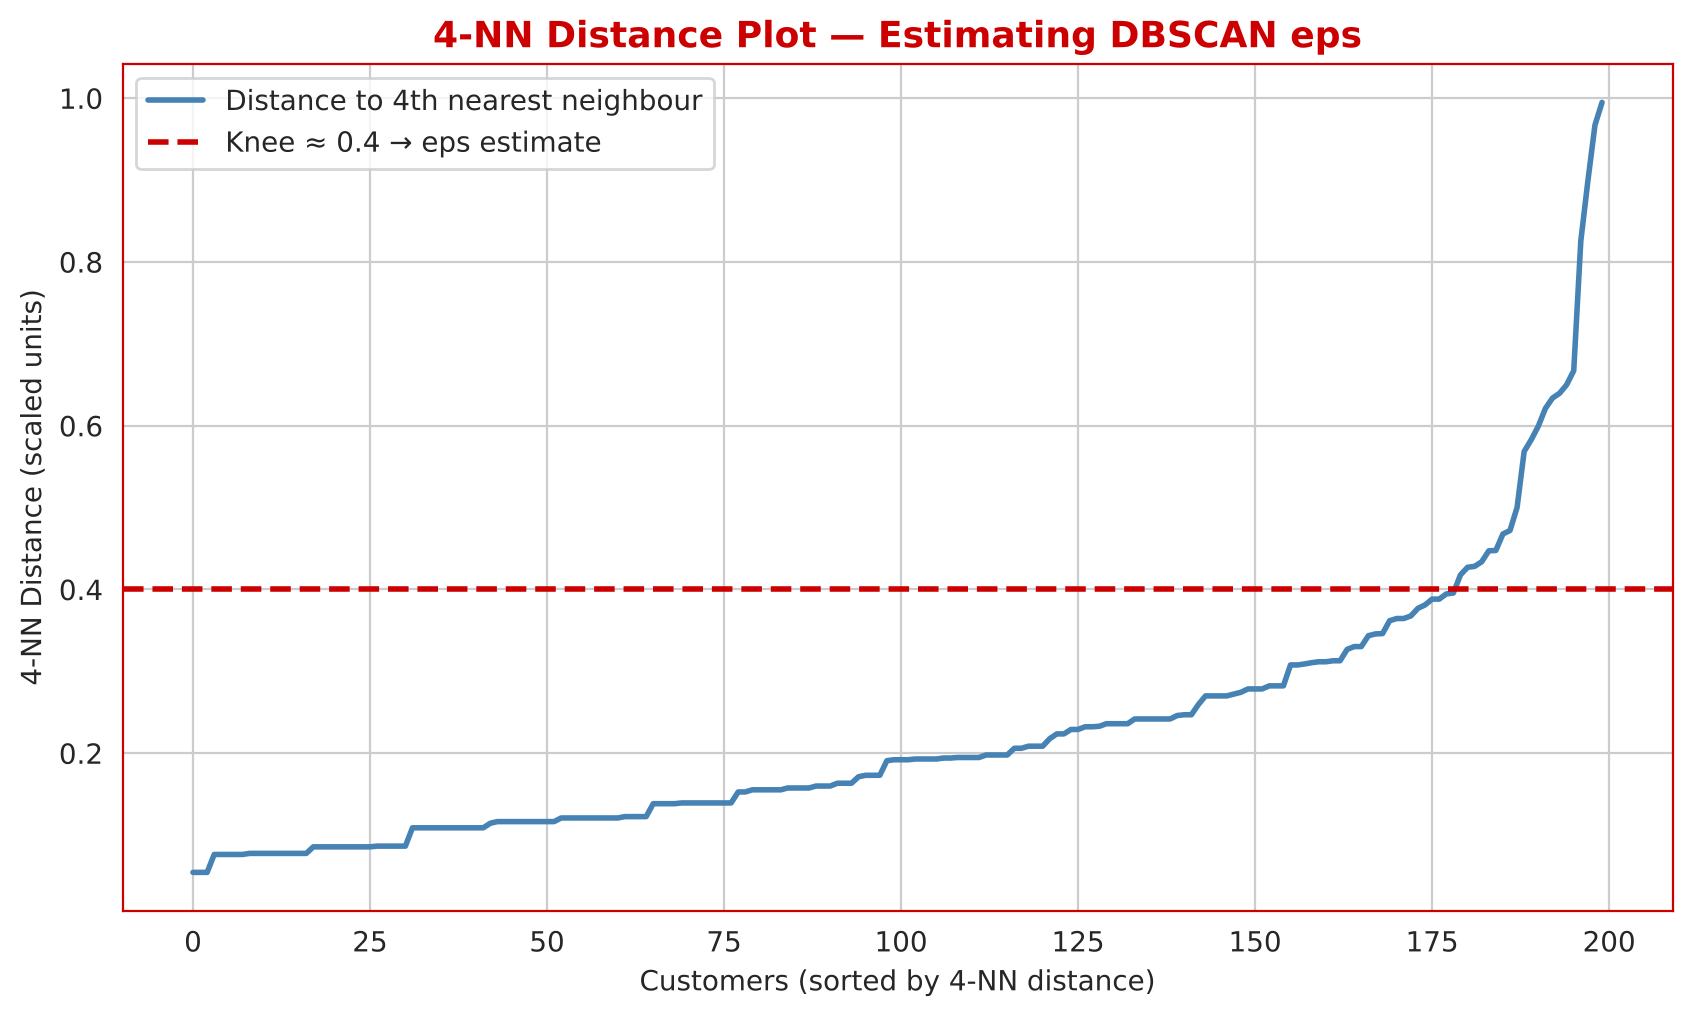

In [34]:
plt.figure(figsize=(10, 5.5))
plt.plot(k_distances, color='steelblue', linewidth=2, label='Distance to 4th nearest neighbour')
plt.axhline(y=0.4, color=red, linestyle='--', linewidth=2, label='Knee ≈ 0.4 → eps estimate')
plt.title('4-NN Distance Plot — Estimating DBSCAN eps')
plt.xlabel('Customers (sorted by 4-NN distance)')
plt.ylabel('4-NN Distance (scaled units)')
plt.legend()
plt.show()

📌 **Reading the plot:** most customers have their 4th neighbour very close (the long flat part, under ~0.3). Around **0.4** the curve bends sharply upwards — the points after the bend live in sparse areas, far from any crowd. That bend is the **knee**, so **eps ≈ 0.4** is the first estimate.

📌 **min_samples:** a common rule of thumb is **min_samples ≈ 2 × number of features = 2 × 2 = 4** — the same 4 used for this plot. The grid search below tests both choices against the alternatives.

### 5.2 Grid search eps & min_samples

In [35]:
# ─── 5.2 Grid search — eps × min_samples ───
from sklearn.cluster import DBSCAN

results = []

for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for min_samples in [3, 4, 5, 6]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(df_2f)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        # Silhouette sirf non-noise points par — aur kam se kam 2 clusters chahiye
        mask = labels != -1
        if len(set(labels[mask])) >= 2:
            score = round(silhouette_score(df_2f[mask], labels[mask]), 4)
        else:
            score = None

        results.append([eps, min_samples, n_clusters, n_noise, score])

grid = pd.DataFrame(results, columns=['eps', 'min_samples', 'n_clusters', 'n_noise', 'silhouette'])
grid

,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.4697
1,0.2,4,5,73,0.6173
2,0.2,5,7,77,0.5856
3,0.2,6,4,95,0.6138
4,0.3,3,9,14,0.4720
5,0.3,4,8,23,0.5197
6,0.3,5,7,35,0.5243
7,0.3,6,6,48,0.5302
8,0.4,3,4,10,0.3954
9,0.4,4,3,14,0.4576


*(Silhouette shows NaN where DBSCAN finds only 1 cluster — the score needs at least 2 clusters to compare.)*

📌 **How I chose the combination:**
- **eps = 0.2 is too strict** — 44 to 95 customers (22–48%) end up as noise.
- **eps = 0.3 breaks the real groups into pieces** — 6 to 9 clusters, several of them tiny.
- **eps = 0.5 and 0.6 are too loose** — everything melts into 1 or 2 big clusters.
- **eps = 0.4 is the sweet spot** — and it matches the knee of the 4-NN plot.

Within eps = 0.4, I chose **min_samples = 4**: it gives **3 coherent clusters with only 14 noise points (7%)**, it matches the 4-NN plot and the 2 × features rule. min_samples = 3 has less noise (10) but one of its 4 "clusters" is just 3 customers — not a real segment. min_samples = 5 and 6 score a little higher on Silhouette, but they also throw more customers into noise (15 and 19) — and since noise is left out of the score, labelling difficult border points as noise can push Silhouette up without the clustering really getting better. So I don't chase the highest Silhouette alone; I balance it against the amount of noise.

**Final choice: eps = 0.4, min_samples = 4.**

In [36]:
# Final choice wala row
grid[(grid['eps'] == 0.4) & (grid['min_samples'] == 4)]

,eps,min_samples,n_clusters,n_noise,silhouette
9,0.4,4,3,14,0.4576


### 5.3 Fit final DBSCAN model

In [37]:
# ─── 5.3 Final DBSCAN model ───
dbscan = DBSCAN(eps=0.4, min_samples=4)
df['DBSCAN_Cluster'] = dbscan.fit_predict(df_2f)

db_labels = df['DBSCAN_Cluster'].values
print('Clusters found :', len(set(db_labels)) - (1 if -1 in db_labels else 0))
print('Noise points   :', np.sum(db_labels == -1))
print()
print(df['DBSCAN_Cluster'].value_counts().sort_index())

Clusters found : 3
Noise points   : 14

DBSCAN_Cluster
-1     14
 0    126
 1     33
 2     27
Name: count, dtype: int64


### 5.4 Visualise DBSCAN clusters

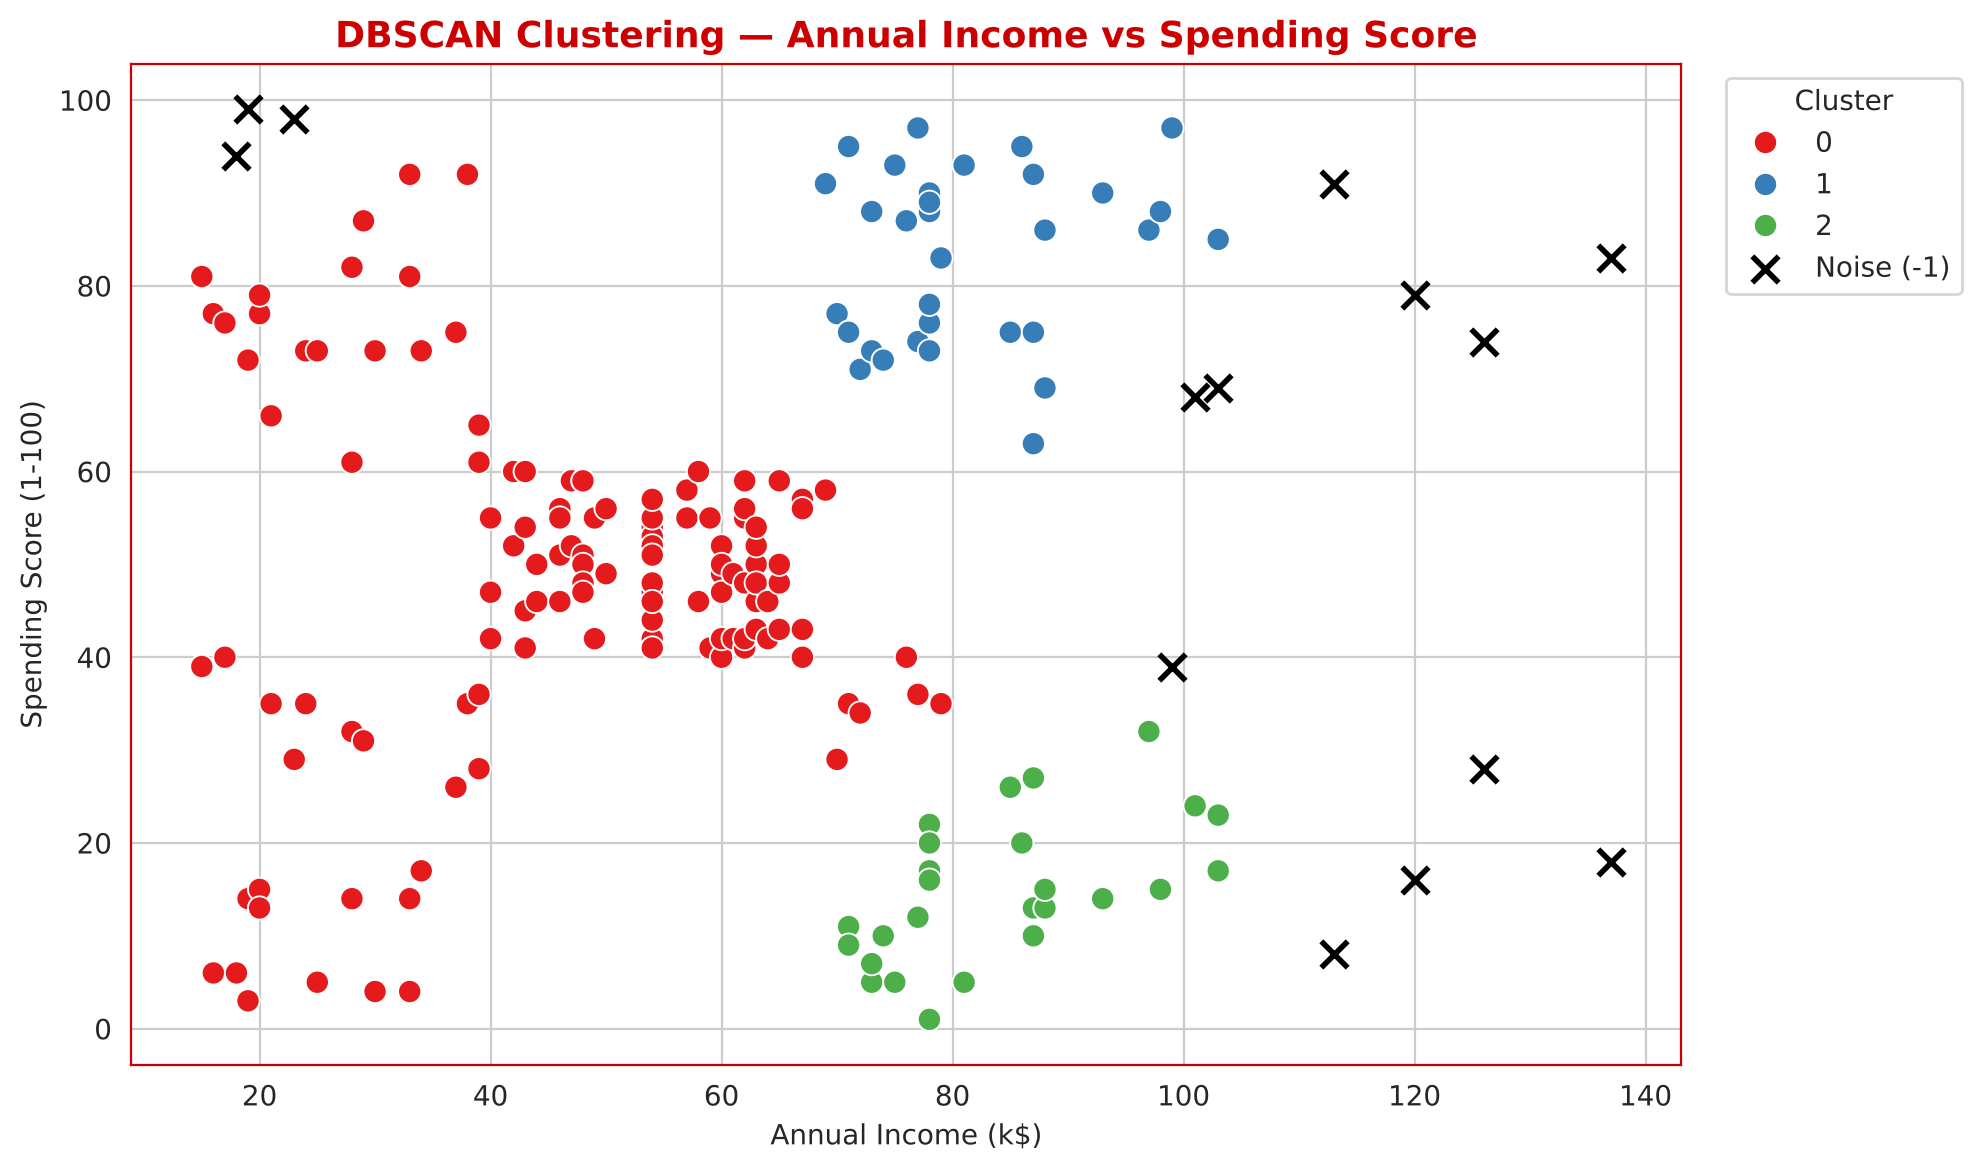

In [38]:
# ─── 5.4 DBSCAN scatter — noise ko black x se dikhao ───
clustered = df[df['DBSCAN_Cluster'] != -1]
noise = df[df['DBSCAN_Cluster'] == -1]

plt.figure(figsize=(10, 6.5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster', data=clustered, palette='Set1', s=70)
plt.scatter(noise['Annual_Income'], noise['Spending_Score'], c='black', marker='x', s=90, linewidths=2, label='Noise (-1)')
plt.title('DBSCAN Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [39]:
# ─── DBSCAN clusters ko bhi same rule se naam do (noise alag) ───
dbscan_profile = df.groupby('DBSCAN_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
dbscan_profile['Customers'] = df.groupby('DBSCAN_Cluster').size()

dbscan_names = {}
for c in dbscan_profile.index:
    if c == -1:
        dbscan_names[c] = 'Noise'
    else:
        dbscan_names[c] = get_segment_name(dbscan_profile.loc[c, 'Annual_Income'], dbscan_profile.loc[c, 'Spending_Score'])

dbscan_profile['Segment'] = dbscan_profile.index.map(dbscan_names)
df['DBSCAN_Segment'] = df['DBSCAN_Cluster'].map(dbscan_names)
dbscan_profile

,Age,Annual_Income,Spending_Score,Customers,Segment
DBSCAN_Cluster,,,,,
-1,34.7,96.8,61.7,14,Noise
0,40.4,46.2,48.0,126,"Average Income, Average Spenders"
1,32.7,81.1,83.0,33,"High Income, High Spenders"
2,41.3,83.9,14.4,27,"High Income, Low Spenders"


In [40]:
# Noise customers kaun hai? — K-Means ne inhe kis segment mein daala tha
noise[['Age', 'Annual_Income', 'Spending_Score', 'KMeans_Segment']].sort_values('Annual_Income')

,Age,Annual_Income,Spending_Score,KMeans_Segment
7,23,18,94,"Low Income, High Spenders"
11,35,19,99,"Low Income, High Spenders"
19,35,23,98,"Low Income, High Spenders"
184,41,99,39,"High Income, Low Spenders"
187,28,101,68,"High Income, High Spenders"
191,32,103,69,"High Income, High Spenders"
192,33,113,8,"High Income, Low Spenders"
193,38,113,91,"High Income, High Spenders"
194,47,120,16,"High Income, Low Spenders"
195,35,120,79,"High Income, High Spenders"


📌 **What eps and min_samples control:**
- **eps = 0.4** is the radius of every customer's neighbourhood (in scaled units). Two customers closer than 0.4 count as neighbours.
- **min_samples = 4** is how many customers (including itself) must be inside that radius for a point to be a **core point**. Core points grow clusters; **border points** are inside a core point's radius but don't have enough neighbours themselves — they join a cluster but can't grow it.

📌 **Why noise points arise:** a customer is labelled **noise (−1)** when they are not a core point *and* not within eps of any core point — they sit in a sparse area, too far from every dense crowd. Here the 14 noise customers are the **extreme edges of the data**: 11 of the highest earners (incomes of 99–137k) and 3 customers with very low income (18–23k) but near-maximum spending (94–99). K-Means quietly forced these people into clusters; DBSCAN refuses to — which is exactly what you want when hunting for unusual customers.

📌 **What DBSCAN found:** only **3 clusters**. *High Income, High Spenders* and *High Income, Low Spenders* come out as clean, separate groups. But the middle group and both low-income groups join into **one big cluster of 126 customers** — there is no low-density gap between them in this data, they are connected by chains of close neighbours, and DBSCAN follows density, not centroids.

### 5.5 DBSCAN vs K-Means — shape detection

1. **No k needed.** DBSCAN does not ask for the number of clusters — it worked out **3** from the density of the data. K-Means had to be told k = 5 up front (using the Elbow and Silhouette results).
2. **Cluster shape.** DBSCAN can find clusters of any shape, because it simply follows connected dense regions. K-Means assumes round (spherical) clusters around a centroid. Here that cuts both ways: DBSCAN's big 126-customer cluster is not round at all — it's three of K-Means' groups linked together by density.
3. **Noise.** DBSCAN labels low-density points as noise (**14 customers**). K-Means forces every customer into some cluster — even the customer earning 137k on the far edge.
4. **Do all three algorithms agree on the number of segments?** **No.** K-Means: 5, Hierarchical: 5, DBSCAN: 3 + noise. The **most stable segments** are **High Income, High Spenders** and **High Income, Low Spenders** — they appear as separate groups in all three algorithms. The three left-side / middle segments are only separated by the centroid- and variance-based methods.

#### Conceptual comparison of all three algorithms

| Aspect | K-Means | Agglomerative Hierarchical (Ward) | DBSCAN |
|---|---|---|---|
| **1. Core idea** | Centroid-based — each customer joins the nearest centroid, centroids move to the mean, repeat until stable | Connectivity-based — every customer starts alone, the two closest clusters are merged again and again into a tree | Density-based — clusters grow out of dense "core" points; points in sparse areas become noise |
| **2. Number of clusters** | Must be chosen up front (k) — Elbow / Silhouette | Not needed to build the tree — chosen afterwards by cutting the dendrogram | Not needed — comes out of eps and min_samples |
| **3. Cluster shape it assumes** | Round (spherical), similar-sized clusters | With Ward: compact, similar-sized clusters | Any shape — as long as it's dense and separated by sparse gaps |
| **4. Outliers / noise** | No noise label — every point is forced into a cluster, and outliers pull the centroids | No noise label — every point ends up somewhere in the tree | Yes — low-density points get label −1 |
| **5. Key parameters** | k, init (k-means++), n_init, random_state | n_clusters (or cut height), linkage, metric | eps, min_samples, metric |
| **6. Speed on big data** | Fast — scales well | Slow — needs all pairwise distances (memory grows ~n²) | Medium — and struggles when clusters have different densities |
| **7. Same result every run?** | Depends on the random starting centroids — fixed here with random_state = 42 and n_init = 10 | Yes — fully deterministic | Yes for core and noise points (a border point between two clusters can depend on data order) |
| **8. Result on this dataset** | 5 clusters, Silhouette 0.555 | 5 clusters, Silhouette 0.554 — 98% the same as K-Means | 3 clusters + 14 noise, Silhouette 0.458 (noise excluded) |

---
## 6️⃣ Task 6: Algorithm Comparison & Business Insights

**Objective:** Put all three algorithms side by side, score them with the same metrics, and turn the best segmentation into marketing actions.

**Expected output:** a 1×3 comparison figure, a metrics summary table (Silhouette, Davies–Bouldin, Calinski–Harabasz), a Business Insights report, and an extension test with all 4 features.

### 6.1 Three-panel comparison figure

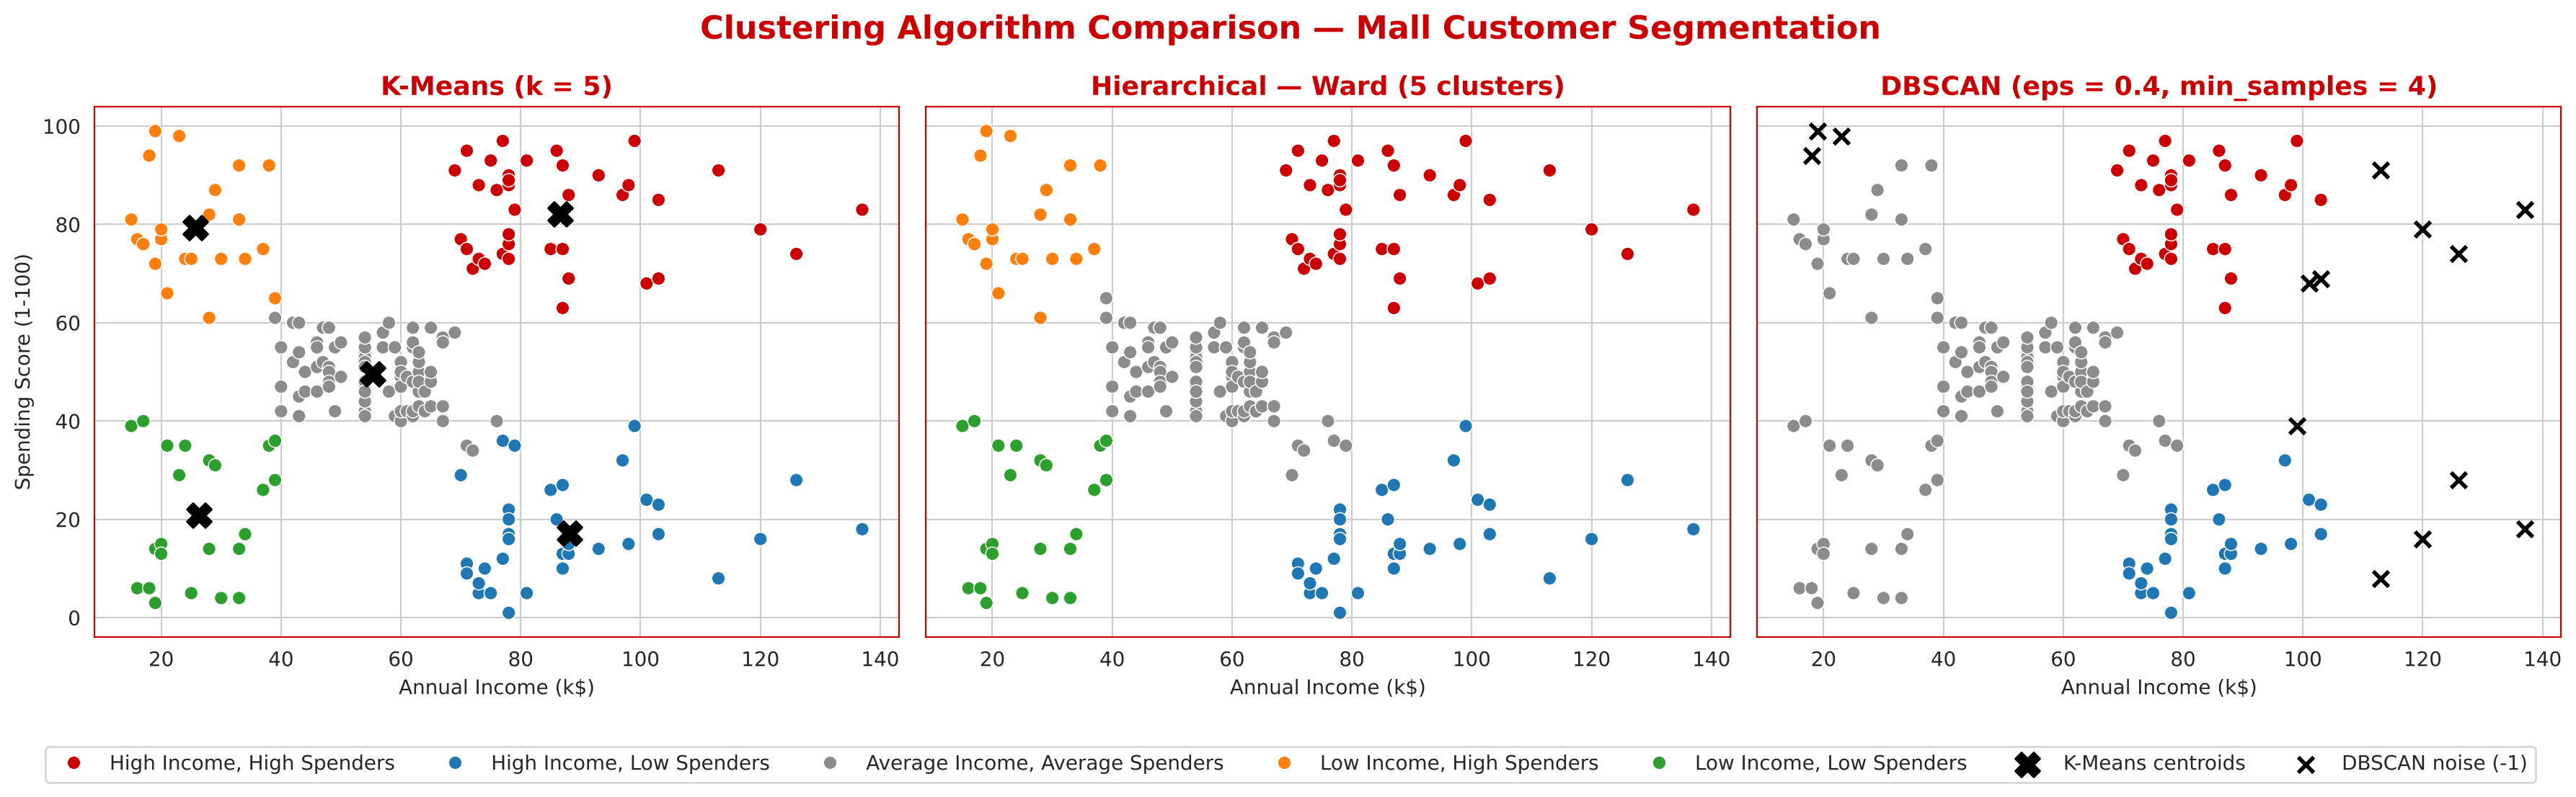

In [41]:
# ─── 6.1 Teeno algorithms ek saath — same axes, same segment colours ───
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

# Panel 1 — K-Means
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Segment', hue_order=segment_order,
                data=df, palette=segment_colors, s=45, ax=axes[0])
axes[0].scatter(centroids['Annual_Income'], centroids['Spending_Score'], c='black', marker='X', s=150, label='K-Means centroids')
axes[0].set_title('K-Means (k = 5)')

# Panel 2 — Hierarchical
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Segment', hue_order=segment_order,
                data=df, palette=segment_colors, s=45, ax=axes[1], legend=False)
axes[1].set_title('Hierarchical — Ward (5 clusters)')

# Panel 3 — DBSCAN (noise = black x)
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Segment', hue_order=segment_order,
                data=df[df['DBSCAN_Cluster'] != -1], palette=segment_colors, s=45, ax=axes[2], legend=False)
noise_marker = axes[2].scatter(noise['Annual_Income'], noise['Spending_Score'], c='black', marker='x', s=60, linewidths=2)
axes[2].set_title('DBSCAN (eps = 0.4, min_samples = 4)')

for ax in axes:
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

# Ek common legend — figure ke neeche
handles, labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(handles + [noise_marker], labels + ['DBSCAN noise (-1)'], loc='lower center', ncol=7,
           bbox_to_anchor=(0.5, -0.1), fontsize=10)

fig.suptitle('Clustering Algorithm Comparison — Mall Customer Segmentation', color=red, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Same customers, same axes, and the same colour always means the same segment. K-Means and Hierarchical look almost identical. DBSCAN paints the whole left side and centre in one colour (its 126-customer cluster) and marks the outer edges as noise.

### 6.2 Metrics summary table
Three internal metrics (no true labels exist, so these judge the clusters by their own shape):

| Metric | Range | Better when | What it rewards |
|---|---|---|---|
| **Silhouette Score** | −1 to 1 | higher | customers close to their own cluster and far from others |
| **Davies–Bouldin Index** | 0 to ∞ | lower | clusters that are compact and far apart from each other |
| **Calinski–Harabasz Index** | 0 to ∞ | higher | spread *between* clusters much bigger than spread *within* them |

In [42]:
# ─── 6.2 Metrics summary — teeno algorithms, same metrics ───
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

# DBSCAN ke noise points (-1) metrics se bahar — brief ke according
db_mask = df['DBSCAN_Cluster'] != -1
db_points = df_2f[db_mask]
db_clusters = df.loc[db_mask, 'DBSCAN_Cluster']

metrics = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical (Ward)', 'DBSCAN'],
    'n_clusters': [df['KMeans_Cluster'].nunique(), df['Hier_Cluster'].nunique(), db_clusters.nunique()],
    'Noise Points': [0, 0, np.sum(df['DBSCAN_Cluster'] == -1)],
    'Silhouette Score': [silhouette_score(df_2f, df['KMeans_Cluster']),
                         silhouette_score(df_2f, df['Hier_Cluster']),
                         silhouette_score(db_points, db_clusters)],
    'Davies-Bouldin Index': [davies_bouldin_score(df_2f, df['KMeans_Cluster']),
                             davies_bouldin_score(df_2f, df['Hier_Cluster']),
                             davies_bouldin_score(db_points, db_clusters)],
    'Calinski-Harabasz Index': [calinski_harabasz_score(df_2f, df['KMeans_Cluster']),
                                calinski_harabasz_score(df_2f, df['Hier_Cluster']),
                                calinski_harabasz_score(db_points, db_clusters)],
})
metrics.round(4)

,Algorithm,n_clusters,Noise Points,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0,0.5547,0.5722,248.6493
1,Hierarchical (Ward),5,0,0.5538,0.5779,244.4103
2,DBSCAN,3,14,0.4576,0.6546,132.0363


📌 **Which algorithm performs best? K-Means** — it wins all three metrics: the highest Silhouette (**0.555**), the lowest Davies–Bouldin (**0.572**) and the highest Calinski–Harabasz (**248.6**).

📌 **Hierarchical is a very close second** (0.554 / 0.578 / 244.4). That makes sense: Ward linkage minimises the same within-cluster variance K-Means does, and the two disagree on only 4 customers.

📌 **DBSCAN scores lowest** (0.458 / 0.655 / 132.0), even with its noise removed, because its 126-customer cluster mixes three different spending groups into one. On this dataset the groups are fairly round, similar in size and evenly dense — exactly the kind of data K-Means is built for, and the kind where DBSCAN's density bridges cause merging.

### 6.3 Business Insights for Mall Management

**(a) The five customer segments** — from K-Means, the most interpretable result:

| Segment | Customers | Avg Age | Avg Income (k$) | Avg Spending Score | Description |
|---|---|---|---|---|---|
| 💎 High Income, High Spenders | 39 (19.5%) | 32.7 | 86.5 | 82.1 | Affluent, mostly younger shoppers who spend freely. The mall's most valuable customers. |
| 🧐 High Income, Low Spenders | 35 (17.5%) | 41.1 | 88.2 | 17.1 | Earn as much as the premium group but spend the least. Careful and value-driven — possibly spending at other malls. |
| 🧺 Average Income, Average Spenders | 81 (40.5%) | 42.7 | 55.3 | 49.5 | The largest group by far. Moderate income, moderate spending — the steady base of daily footfall. |
| 🔥 Low Income, High Spenders | 22 (11%) | 25.3 | 25.7 | 79.4 | The youngest segment, spending well beyond their income. Trend-driven and quick to react to offers. |
| 💰 Low Income, Low Spenders | 23 (11.5%) | 45.2 | 26.3 | 20.9 | Budget-conscious and price-sensitive. They visit for essentials and discounts. |

**(b) One targeted marketing action per segment:**

| Segment | Marketing action |
|---|---|
| 💎 High Income, High Spenders | **VIP loyalty programme** — tiered rewards, early access to new collections and personal shopping, to keep them from drifting to a competitor. |
| 🧐 High Income, Low Spenders | **Quality-and-value campaign** — promote premium brands, warranties and exclusive in-store experiences, with personalised "spend more, save more" vouchers to unlock the budget they already have. |
| 🧺 Average Income, Average Spenders | **Points card for repeat visits** — monthly offers and festival campaigns that reward regular footfall. |
| 🔥 Low Income, High Spenders | **Trend-led social media promotions** — Instagram campaigns, new-arrival alerts and student discounts that match how this young group shops. |
| 💰 Low Income, Low Spenders | **Budget promotions** — clearance sales, combo packs and discount days that bring them in more often. |

**(c) Recommended algorithm for deployment: K-Means**
- **Best scores** on all three metrics (Silhouette 0.555, Davies–Bouldin 0.572, Calinski–Harabasz 248.6).
- **Most interpretable** — every segment has a centroid, an "average customer" the marketing team can picture and target.
- **Easy to use on new customers** — a new shopper can be placed into a segment instantly with `kmeans.predict()` (shown below), without re-running anything.
- **Where the others still help:** **Hierarchical** is the best choice when management wants a visual hierarchy (the dendrogram) for a presentation, and its 98% agreement with K-Means is a strong validation. **DBSCAN** is best when cluster shapes are unknown — and as an *outlier detector*: its 14 noise customers (top earners and extreme spenders) are worth a closer manual look.

In [43]:
# ─── Deployment demo: naya customer aaya — kaunsa segment? ───
# Age 30, Income 80k$, Spending Score 22
new_customer = pd.DataFrame([[30, 80, 22]], columns=['Age', 'Annual_Income', 'Spending_Score'])

new_scaled = scaler.transform(new_customer)              # wahi scaler jo training mein use hua
new_2f = pd.DataFrame(new_scaled[:, 1:], columns=['Annual_Income', 'Spending_Score'])

new_cluster = kmeans.predict(new_2f)[0]
print('Predicted cluster :', new_cluster)
print('Segment           :', kmeans_names[new_cluster])

Predicted cluster : 3
Segment           : High Income, Low Spenders


### 6.4 Extension — Clustering with all 4 features
In Task 2 I chose 2 features for visual clarity. Here I test the alternative from the brief: K-Means on **all 4 features** — Gender (0/1) plus scaled Age, Annual_Income and Spending_Score.

In [44]:
# ─── Extension: 4 features vs 2 features ───
df_4f = df_scaled.copy()
df_4f['Gender'] = df['Gender']          # Gender already 0/1 hai

sil_4f = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(df_4f)
    sil_4f.append(silhouette_score(df_4f, labels))

print('Best with 2 features:', round(max(sil_scores), 4), 'at k =', k_range[sil_scores.index(max(sil_scores))])
print('Best with 4 features:', round(max(sil_4f), 4), 'at k =', k_range[sil_4f.index(max(sil_4f))])

Best with 2 features: 0.5547 at k = 5
Best with 4 features: 0.3565 at k = 6


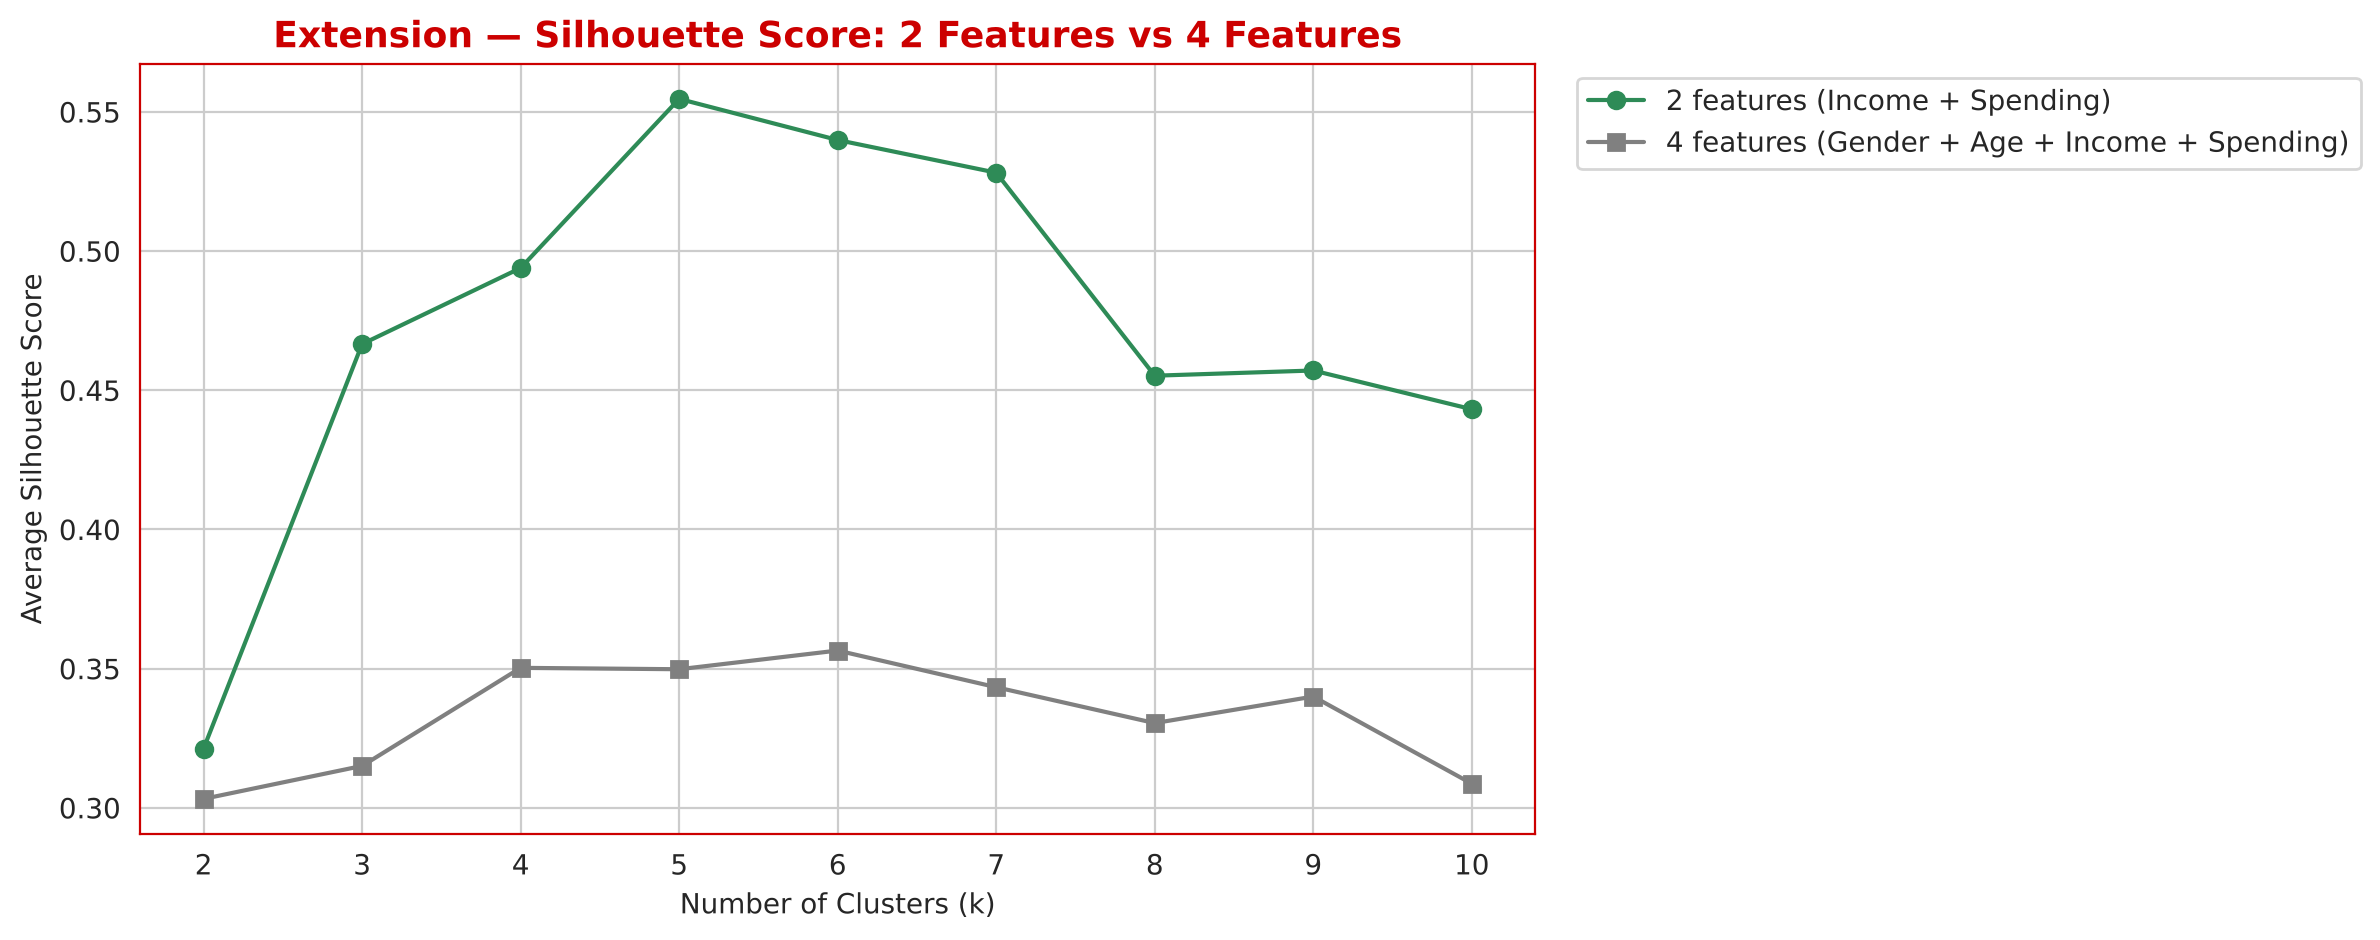

In [45]:
plt.figure(figsize=(9, 5))
plt.plot(k_range, sil_scores, marker='o', color='seagreen', label='2 features (Income + Spending)')
plt.plot(k_range, sil_4f, marker='s', color='gray', label='4 features (Gender + Age + Income + Spending)')
plt.title('Extension — Silhouette Score: 2 Features vs 4 Features')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_range)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

📌 **Result:** more features made the clusters **worse**, not better — the best Silhouette drops from **0.555 (2 features, k = 5)** to **0.356 (4 features, k = 6)**, and the 4-feature line is lower at every k. Age and Gender add spread without adding clear group structure (Gender had near-zero correlation with everything in the EDA), so customers get pulled in more directions and the groups overlap.

This confirms the Task 2 decision: **Annual_Income + Spending_Score carry the segmentation signal.** More columns is not automatically more insight.

---
## 7️⃣ Task 7: Notebook Quality, Structure & Submission

**Objective:** Keep the notebook clean, consistent and reproducible for submission.

**Expected output:** a short checklist of the submission standards, plus the exact library versions used (the same versions pinned in `requirements.txt`).

- ✅ **7.1 Notebook structure** — every task opens with its title, a one-line objective and the expected output. No commented-out dead code, no duplicate cells.
- ✅ **7.2 Visualisation standards** — every plot has a descriptive title, labelled x- and y-axes and a legend where it applies. `sns.set_style('whitegrid')` is set once at the top, and red **#CC0000** is used for titles and plot borders.
- ✅ **7.3 Restart & Run All** — the notebook runs from top to bottom in a fresh kernel with zero errors.
- ✅ **7.4 Export as HTML** — `UL_PR1.html` sits next to `UL_PR1.ipynb` in the GitHub repository, so it can be read without running Jupyter.
- ✅ **7.5 Requirements file** — `requirements.txt` pins the versions printed below.

In [46]:
# ─── 7.5 Library versions — requirements.txt mein yahi versions pinned hai ───
import matplotlib
import sklearn
import scipy

print('pandas       :', pd.__version__)
print('numpy        :', np.__version__)
print('matplotlib   :', matplotlib.__version__)
print('seaborn      :', sns.__version__)
print('scikit-learn :', sklearn.__version__)
print('scipy        :', scipy.__version__)

pandas       : 3.0.5
numpy        : 2.5.3
matplotlib   : 3.11.2
seaborn      : 0.13.2
scikit-learn : 1.9.1
scipy        : 1.18.1


---
## 🎬 Final Summary

- 📌 **Five customer segments** were found by K-Means and confirmed by Hierarchical clustering, which agrees on **196 of 200 customers**.
- 📌 **The Elbow Method and the Silhouette Score both chose k = 5**, and the dendrogram's biggest gap pointed to 5 as well.
- 📌 **DBSCAN found 3 dense groups + 14 outliers** — less useful for segmentation here, but very useful for spotting unusual customers.
- 📌 **K-Means is the recommended model** for the mall: the best scores, the easiest to explain, and instant segment assignment for new customers.
- 📌 **Two features beat four:** Annual Income + Spending Score gave a Silhouette of 0.555 vs 0.356 with all four features.

*— Parth Shah · Unsupervised Learning · PR 1*